#LIBRARIES

In [ ]:
# Core Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Imputation
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Feature Selection
from sklearn.feature_selection import mutual_info_classif

# Data Splitting & Cross Validation
from sklearn.model_selection import train_test_split, StratifiedKFold

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, roc_auc_score)

# Oversampling, Explainability & Statistics
from imblearn.over_sampling import SMOTE
import shap
from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


#DATASET IMPORT

In [ ]:
import pandas as pd

file_path = "/content/structured_endometriosis_data..xlsx"

df = pd.read_excel(file_path)

print("✅ Dataset loaded successfully!")
df.head()

✅ Dataset loaded successfully!


,Age,Menstrual_Irregularity,Chronic_Pain_Level,Hormone_Level_Abnormality,Infertility,BMI,Diagnosis
0,24,1,8.361531,0,0,19.451314,0
1,37,1,4.995508,0,0,22.388436,0
2,46,1,3.363996,1,0,21.320443,0
3,32,1,5.246037,0,0,20.177715,1
4,28,1,3.898932,1,0,23.538103,1


#DATA UNDERSTANDING


In [ ]:
# Generate Basic Descriptive Statistics

stats_table = pd.DataFrame({
    'Count': df.count(),
    'Mean': df.mean(),
    'Median': df.median(),
    'Mode': df.mode().iloc[0],
    'Std Dev': df.std(),
    'Min': df.min(),
    'Max': df.max(),
    'Skewness': df.skew()

})

print("Descriptive Statistics:")
display(stats_table)

Descriptive Statistics:


,Count,Mean,Median,Mode,Std Dev,Min,Max,Skewness
Age,10000,33.692300,34.000000,34.0,9.205308,18.0,49.000000,-0.041001
Menstrual_Irregularity,10000,0.697500,1.000000,1.0,0.459364,0.0,1.000000,-0.860057
Chronic_Pain_Level,10000,5.030619,5.035825,0.0,1.983955,0.0,10.000000,-0.004982
Hormone_Level_Abnormality,10000,0.591100,1.000000,1.0,0.491655,0.0,1.000000,-0.370659
Infertility,10000,0.298300,0.000000,0.0,0.457535,0.0,1.000000,0.881858
BMI,10000,23.052865,23.036315,15.0,3.891615,15.0,37.146127,0.093770
Diagnosis,10000,0.407900,0.000000,0.0,0.491469,0.0,1.000000,0.374870


#DATA PREPROCESSING

In [ ]:
# Step 1: Data Type Verification

data_type_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.values
})

display(data_type_summary)

categorical_features = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

if not categorical_features:
    print("No categorical features found.")

,Feature,Data Type
0,Age,int64
1,Menstrual_Irregularity,int64
2,Chronic_Pain_Level,float64
3,Hormone_Level_Abnormality,int64
4,Infertility,int64
5,BMI,float64
6,Diagnosis,int64


No categorical features found.


#DUPLICATE ROW

In [ ]:
# Step 2: Duplicate Record Analysis

def analyze_duplicates(dataset):

    duplicate_count = dataset.duplicated().sum()

    duplicate_percentage = round(
        (duplicate_count / len(dataset)) * 100,
        2
    )

    print("=" * 60)
    print("DUPLICATE RECORD ANALYSIS")
    print("=" * 60)

    print(f"Duplicate Records: {duplicate_count}")
    print(f"Duplicate Percentage: {duplicate_percentage}%")

    if duplicate_count == 0:
        print("No Duplicate Records Found")
    else:
        print("Duplicate Records Detected")

analyze_duplicates(df)

DUPLICATE RECORD ANALYSIS
Duplicate Records: 0
Duplicate Percentage: 0.0%
No Duplicate Records Found


#MISSING VALUE

In [ ]:
# Step 3: Missing Value Analysis

def analyze_missing_values(dataset):

    missing_summary = pd.DataFrame({
        "Missing Count": dataset.isnull().sum(),
        "Missing Percentage (%)": round(
            (dataset.isnull().sum() / len(dataset)) * 100,
            2
        )
    })

    print("=" * 60)
    print("MISSING VALUE ANALYSIS")
    print("=" * 60)

    display(missing_summary)

    total_missing = dataset.isnull().sum().sum()

    print(f"\nTotal Missing Values: {total_missing}")

    if total_missing == 0:
        print(" No Missing Values Found")
    else:
        print("⚠ Missing Values Detected")

analyze_missing_values(df)

MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage (%)
Age,0,0.0
Menstrual_Irregularity,0,0.0
Chronic_Pain_Level,0,0.0
Hormone_Level_Abnormality,0,0.0
Infertility,0,0.0
BMI,0,0.0
Diagnosis,0,0.0



Total Missing Values: 0
 No Missing Values Found


#OUTLIER DETECTION

Total BMI Outliers found: 30
Lower Bound: 12.25, Upper Bound: 33.79

--- The 30 Outlier Rows ---


,Age,Menstrual_Irregularity,Chronic_Pain_Level,Hormone_Level_Abnormality,Infertility,BMI,Diagnosis
911,30,1,3.740060,1,0,34.978145,1
1066,38,1,2.338702,1,0,33.972815,1
1203,27,1,5.663928,1,0,33.834023,0
1650,28,0,4.295901,0,0,35.412805,1
1661,44,1,5.071687,0,0,35.006675,0
1894,42,1,7.418738,1,0,34.709476,1
2129,37,1,5.506367,1,0,34.407848,0
2392,49,1,6.532912,1,1,36.183618,1
2542,18,1,7.900681,1,1,33.841970,1
3120,33,0,5.164406,1,1,34.102490,0


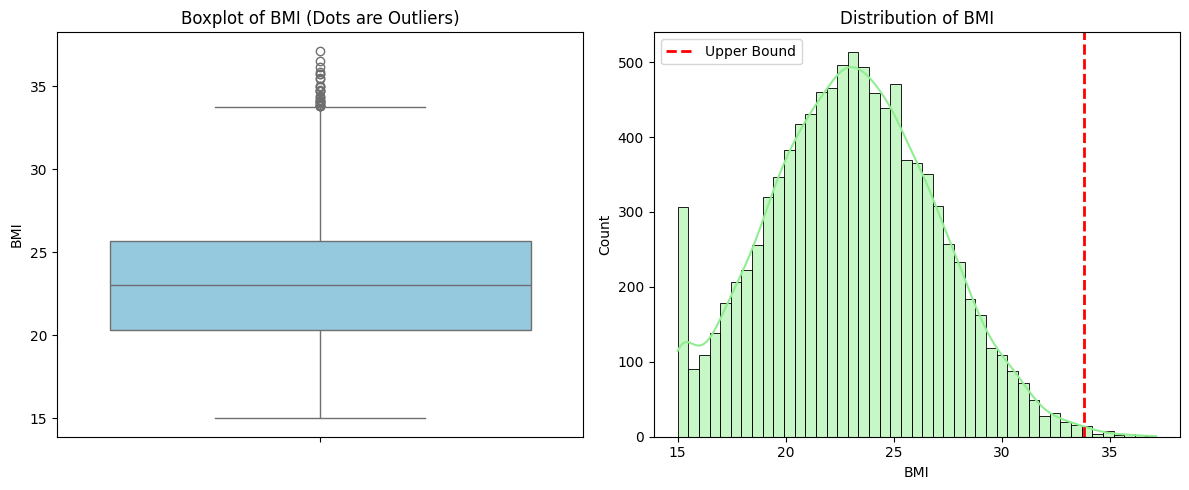

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. BMI outlier boundary
Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# 2.outlier filter

bmi_outliers = df[(df['BMI'] < lower_bound) | (df['BMI'] > upper_bound)]

print(f"Total BMI Outliers found: {len(bmi_outliers)}")
print(f"Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}\n")

print("--- The 30 Outlier Rows ---")
# show all the outlier
display(bmi_outliers)


# 3.outlier Visulization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot
sns.boxplot(y=df['BMI'], ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot of BMI (Dots are Outliers)")

# Distribution Plot
sns.histplot(df['BMI'], kde=True, ax=axes[1], color="lightgreen")
# upper boundary line
axes[1].axvline(upper_bound, color='red', linestyle='dashed', linewidth=2, label='Upper Bound')
axes[1].legend()
axes[1].set_title("Distribution of BMI")

plt.tight_layout()
plt.show()

#FEATURE ENGINEERING

In [ ]:
import pandas as pd
import numpy as np

# 1. feature enginnering function
def engineer_features(df):
    df_engineered = df.copy()

    # --- 1. Multiplication / Interaction Features ---
    df_engineered['Age_BMI_Interaction'] = df_engineered['Age'] * df_engineered['BMI']
    df_engineered['Age_Menstrual_Interaction'] = df_engineered['Age'] * df_engineered['Menstrual_Irregularity']
    df_engineered['Age_Hormone_Interaction'] = df_engineered['Age'] * df_engineered['Hormone_Level_Abnormality']

    df_engineered['BMI_Menstrual_Interaction'] = df_engineered['BMI'] * df_engineered['Menstrual_Irregularity']
    df_engineered['BMI_Hormone_Interaction'] = df_engineered['BMI'] * df_engineered['Hormone_Level_Abnormality']
    df_engineered['BMI_Infertility_Interaction'] = df_engineered['BMI'] * df_engineered['Infertility']

    df_engineered['Chronic_P_Menstrual_Interaction'] = df_engineered['Chronic_Pain_Level'] * df_engineered['Menstrual_Irregularity']
    df_engineered['Hormone_Infertility_Interaction'] = df_engineered['Hormone_Level_Abnormality'] * df_engineered['Infertility']

    # --- 2. Aggregation Features ---
    df_engineered['Symptom_Burden_Sum'] = (df_engineered['Menstrual_Irregularity'] +
                                           df_engineered['Hormone_Level_Abnormality'] +
                                           df_engineered['Infertility'])

    df_engineered['Composite_Risk_Score'] = (df_engineered['Age'] / 10) * (df_engineered['BMI'] / 20) * df_engineered['Symptom_Burden_Sum']

    # --- 3. Polynomial & Ratio Features ---
    df_engineered['Age_Squared'] = df_engineered['Age'] ** 2
    df_engineered['BMI_Squared'] = df_engineered['BMI'] ** 2
    df_engineered['Chronic_P_Squared'] = df_engineered['Chronic_Pain_Level'] ** 2
    df_engineered['Age_to_BMI_Ratio'] = df_engineered['Age'] / (df_engineered['BMI'] + 1e-5)

    return df_engineered

# 2. feature enginnering apply all the dataset
df_engineered = engineer_features(df)
print(f"Total features after engineering: {df_engineered.shape[1] - 1}")
display(df_engineered.head())

Total features after engineering: 20


,Age,Menstrual_Irregularity,Chronic_Pain_Level,Hormone_Level_Abnormality,Infertility,BMI,Diagnosis,Age_BMI_Interaction,Age_Menstrual_Interaction,Age_Hormone_Interaction,...,BMI_Hormone_Interaction,BMI_Infertility_Interaction,Chronic_P_Menstrual_Interaction,Hormone_Infertility_Interaction,Symptom_Burden_Sum,Composite_Risk_Score,Age_Squared,BMI_Squared,Chronic_P_Squared,Age_to_BMI_Ratio
0,24,1,8.361531,0,0,19.451314,0,466.831527,24,0,...,0.000000,0.0,8.361531,0,1,2.334158,576,378.353602,69.915208,1.233849
1,37,1,4.995508,0,0,22.388436,0,828.372121,37,0,...,0.000000,0.0,4.995508,0,1,4.141861,1369,501.242053,24.955096,1.652638
2,46,1,3.363996,1,0,21.320443,0,980.740386,46,46,...,21.320443,0.0,3.363996,0,2,9.807404,2116,454.561297,11.316467,2.157553
3,32,1,5.246037,0,0,20.177715,1,645.686887,32,0,...,0.000000,0.0,5.246037,0,1,3.228434,1024,407.140191,27.520908,1.585907
4,28,1,3.898932,1,0,23.538103,1,659.066883,28,28,...,23.538103,0.0,3.898932,0,2,6.590669,784,554.042291,15.201671,1.189560


#TRAIN AND SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

# Sepertate terget and feature
X = df_engineered.drop(columns=['Diagnosis'])
y = df_engineered['Diagnosis']

#  Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

Train Shape: (8000, 20) | Test Shape: (2000, 20)


In [ ]:
from imblearn.over_sampling import SMOTE

#smote apply only in tranning dataset
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Train Shape: {X_train.shape}")
print(f"After SMOTE - Train Shape: {X_train_res.shape}")

Before SMOTE - Train Shape: (8000, 20)
After SMOTE - Train Shape: (9474, 20)


# **Scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler

# StandardScaler ---->scaling
scaler = StandardScaler()

# traning-----> fit_transform and test-----> transform
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# Convert the data into a DataFrame while keeping the column names and index unchanged for SHAP analysis or easier model implementation.
X_train_final = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_final = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Feature scaling was successfully completed!")
display(X_train_final.head())

Feature scaling was successfully completed!


,Age,Menstrual_Irregularity,Chronic_Pain_Level,Hormone_Level_Abnormality,Infertility,BMI,Age_BMI_Interaction,Age_Menstrual_Interaction,Age_Hormone_Interaction,BMI_Menstrual_Interaction,BMI_Hormone_Interaction,BMI_Infertility_Interaction,Chronic_P_Menstrual_Interaction,Hormone_Infertility_Interaction,Symptom_Burden_Sum,Composite_Risk_Score,Age_Squared,BMI_Squared,Chronic_P_Squared,Age_to_BMI_Ratio
0,0.898412,0.668141,0.396950,-1.207306,-0.620554,1.549663,1.778515,1.071461,-1.153179,1.176446,-1.217446,-0.666986,0.808120,-0.443640,-0.727207,-0.053078,0.871091,1.646861,0.224111,-0.132695
1,-1.719118,0.668141,0.047821,0.828290,-0.620554,-0.708307,-1.652932,-0.341814,-0.142796,0.367616,0.548300,-0.666986,0.565650,-0.443640,0.525896,-0.687830,-1.452642,-0.740924,-0.144101,-1.245090
2,1.007476,-1.496690,-2.233262,-1.207306,-0.620554,1.088327,1.585717,-1.401770,-1.153179,-1.501051,-1.217446,-0.666986,-1.283957,-0.443640,-1.980309,-1.632903,1.008255,1.089939,-1.434971,0.130052
3,0.462157,0.668141,0.614965,0.828290,-0.620554,-0.813875,-0.088412,0.835915,0.979852,0.329801,0.512568,-0.666986,0.959532,-0.443640,0.525896,0.321875,0.354706,-0.831770,0.477021,0.798761
4,0.134966,0.668141,-0.372205,0.828290,1.611462,1.563245,0.969959,0.659256,0.811455,1.181311,1.317180,2.066703,0.273941,2.254079,1.778998,2.323837,0.001305,1.663795,-0.527053,-0.617452


In [ ]:
import pandas as pd

# 1. Combine Train and Test data with the target variable
train_final_df = pd.concat(
    [X_train_final, y_train_res.reset_index(drop=True)], axis=1
)

test_final_df = pd.concat(
    [X_test_final, y_test.reset_index(drop=True)], axis=1
)

# Combine the complete dataset (Train + Test)
full_final_df = pd.concat(
    [train_final_df, test_final_df], ignore_index=True
)


# 2. Save the datasets to an Excel file
# output_file = 'final_engineered_dataset.xlsx'
# with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
#     full_final_df.to_excel(writer, sheet_name='Full_Dataset', index=False)
#     train_final_df.to_excel(writer, sheet_name='Train_Data', index=False)
#     test_final_df.to_excel(writer, sheet_name='Test_Data', index=False)

# print("File saved successfully!")


# 3. Download the file directly from Google Colab
# from google.colab import files
# files.download(output_file)

#DATA Leakage check

In [ ]:
# Data Leakage and Shape Check

print("===== DATA LEAKAGE & INTEGRITY CHECK =====")

# 1. Check Train and Test shapes after SMOTE
print(f"1. Training target shape after SMOTE: {y_train_res.shape}")
print(f"   Test target shape: {y_test.shape}")

# 2. Check scaled training data
train_mean = X_train_final.mean().mean()
train_std = X_train_final.std().mean()
print(f"\n2. Scaled Train Data -> Mean: {train_mean:.4f}, Std: {train_std:.4f}")

# 3. Check if Train and Test have common rows
train_set_check = set(tuple(x) for x in X_train.values)
test_set_check = set(tuple(x) for x in X_test.values)
intersection_count = len(train_set_check.intersection(test_set_check))
print(f"\n3. Common rows between Train and Test: {intersection_count}")

# 4. Check missing values
print(f"\n4. Missing Values in Train: {X_train_final.isnull().sum().sum()}")
print(f"   Missing Values in Test: {X_test_final.isnull().sum().sum()}")

print("\n Data leakage and integrity check completed!")

===== DATA LEAKAGE & INTEGRITY CHECK =====
1. Training target shape after SMOTE: (9474,)
   Test target shape: (2000,)

2. Scaled Train Data -> Mean: 0.0000, Std: 1.0001

3. Common rows between Train and Test: 0

4. Missing Values in Train: 0
   Missing Values in Test: 0

 Data leakage and integrity check completed!


#LR

In [ ]:
# ==========================================
# STEP 1: LOGISTIC REGRESSION - BASELINE
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Logistic Regression model define
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# 2. Model training
lr_model.fit(X_train_final, y_train_res)

# 3. Training prediction
y_train_pred_lr = lr_model.predict(X_train_final)

# 4. Test prediction
y_test_pred_lr = lr_model.predict(X_test_final)

# 5. Test probability
y_test_prob_lr = lr_model.predict_proba(X_test_final)[:, 1]

# ==========================================
# STEP 2: PERFORMANCE EVALUATION
# ==========================================

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_lr
).ravel()

# Metrics
accuracy_lr = accuracy_score(y_test, y_test_pred_lr)
precision_lr = precision_score(y_test, y_test_pred_lr)
recall_lr = recall_score(y_test, y_test_pred_lr)
specificity_lr = tn / (tn + fp)
f1_lr = f1_score(y_test, y_test_pred_lr)
auc_lr = roc_auc_score(y_test, y_test_prob_lr)

# Train Accuracy
train_accuracy_lr = accuracy_score(
    y_train_res,
    y_train_pred_lr
)

print("==========================================")
print("LOGISTIC REGRESSION - BASELINE")
print("==========================================")

print(f"Train Accuracy : {train_accuracy_lr:.4f}")
print(f"Test Accuracy  : {accuracy_lr:.4f}")
print(f"Precision      : {precision_lr:.4f}")
print(f"Recall         : {recall_lr:.4f}")
print(f"Specificity    : {specificity_lr:.4f}")
print(f"F1-Score       : {f1_lr:.4f}")
print(f"ROC-AUC        : {auc_lr:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_lr))

LOGISTIC REGRESSION - BASELINE
Train Accuracy : 0.6398
Test Accuracy  : 0.6240
Precision      : 0.5402
Recall         : 0.5270
Specificity    : 0.6909
F1-Score       : 0.5335
ROC-AUC        : 0.6463

Confusion Matrix:
[[818 366]
 [386 430]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.69      0.69      1184
           1       0.54      0.53      0.53       816

    accuracy                           0.62      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.62      0.62      0.62      2000



In [ ]:
# ==========================================
# STEP 2: LOGISTIC REGRESSION - DATA LEAKAGE CHECK
# ==========================================

import numpy as np
import pandas as pd

print("=" * 60)
print("LOGISTIC REGRESSION - DATA LEAKAGE CHECK")
print("=" * 60)


# ------------------------------------------------
# CHECK 1: Train-Test Shape
# ------------------------------------------------

print("\n[1] Train-Test Shape Check")

print("X_train_final :", X_train_final.shape)
print("y_train_res   :", y_train_res.shape)

print("X_test_final  :", X_test_final.shape)
print("y_test        :", y_test.shape)


# ------------------------------------------------
# CHECK 2: Target Leakage in Features
# ------------------------------------------------

print("\n[2] Target Leakage Check")

target_name = "Diagnosis"

if target_name in X_train_final.columns:
    print(" LEAKAGE FOUND: Diagnosis exists in training features!")
else:
    print("PASS: Diagnosis is not present in training features.")


if target_name in X_test_final.columns:
    print(" LEAKAGE FOUND: Diagnosis exists in test features!")
else:
    print("PASS: Diagnosis is not present in test features.")


# ------------------------------------------------
# CHECK 3: Train-Test Duplicate / Row Overlap
# ------------------------------------------------

print("\n[3] Train-Test Row Overlap Check")

# Convert to comparable format
train_check = pd.DataFrame(X_train_final).reset_index(drop=True)
test_check = pd.DataFrame(X_test_final).reset_index(drop=True)

# Make sure columns are same
common_columns = train_check.columns.intersection(test_check.columns)

train_temp = train_check[common_columns].copy()
test_temp = test_check[common_columns].copy()

# Hash rows
train_hash = pd.util.hash_pandas_object(
    train_temp,
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_temp,
    index=False
)

overlap = len(
    set(train_hash).intersection(set(test_hash))
)

print("Overlapping rows:", overlap)

if overlap == 0:
    print("PASS: No train-test row overlap detected.")
else:
    print(" LEAKAGE WARNING: Train-test overlapping rows detected!")


# ------------------------------------------------
# CHECK 4: Duplicate Rows Inside Training Data
# ------------------------------------------------

print("\n[4] Training Duplicate Check")

train_duplicates = train_check.duplicated().sum()

print("Duplicate rows in training:", train_duplicates)

if train_duplicates == 0:
    print("PASS: No duplicate rows in training data.")
else:
    print("WARNING: Duplicate rows exist in training data.")


# ------------------------------------------------
# CHECK 5: Duplicate Rows Inside Test Data
# ------------------------------------------------

print("\n[5] Test Duplicate Check")

test_duplicates = test_check.duplicated().sum()

print("Duplicate rows in test:", test_duplicates)

if test_duplicates == 0:
    print(" PASS: No duplicate rows in test data.")
else:
    print("WARNING: Duplicate rows exist in test data.")


# ------------------------------------------------
# CHECK 6: Missing / Infinite Values
# ------------------------------------------------

print("\n[6] Missing / Infinite Value Check")

train_nan = X_train_final.isna().sum().sum()
test_nan = X_test_final.isna().sum().sum()

train_inf = np.isinf(X_train_final.select_dtypes(include=np.number)).sum().sum()
test_inf = np.isinf(X_test_final.select_dtypes(include=np.number)).sum().sum()

print("Train NaN:", train_nan)
print("Test NaN :", test_nan)
print("Train Inf:", train_inf)
print("Test Inf :", test_inf)

if train_nan == 0 and test_nan == 0 and train_inf == 0 and test_inf == 0:
    print("PASS: No NaN or infinite values detected.")
else:
    print(" WARNING: NaN or infinite values detected.")


# ------------------------------------------------
# CHECK 7: Target Consistency
# ------------------------------------------------

print("\n[7] Target Consistency Check")

print("Training target distribution:")
print(y_train_res.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nTest target percentage:")
print(y_test.value_counts(normalize=True) * 100)


# ------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 60)
print("LEAKAGE CHECK COMPLETED")
print("=" * 60)

print("""
Important:
• Test data must not be used for model fitting.
• Test data must not be used for SMOTE.
• Test data must not be used for hyperparameter tuning.
• Test data must not be used for threshold selection.
• Scaler must be fitted using training data only.
""")

LOGISTIC REGRESSION - DATA LEAKAGE CHECK

[1] Train-Test Shape Check
X_train_final : (9474, 20)
y_train_res   : (9474,)
X_test_final  : (2000, 20)
y_test        : (2000,)

[2] Target Leakage Check
PASS: Diagnosis is not present in training features.
PASS: Diagnosis is not present in test features.

[3] Train-Test Row Overlap Check
Overlapping rows: 0
PASS: No train-test row overlap detected.

[4] Training Duplicate Check
Duplicate rows in training: 0
PASS: No duplicate rows in training data.

[5] Test Duplicate Check
Duplicate rows in test: 0
 PASS: No duplicate rows in test data.

[6] Missing / Infinite Value Check
Train NaN: 0
Test NaN : 0
Train Inf: 0
Test Inf : 0
PASS: No NaN or infinite values detected.

[7] Target Consistency Check
Training target distribution:
Diagnosis
0    4737
1    4737
Name: count, dtype: int64

Test target distribution:
Diagnosis
0    1184
1     816
Name: count, dtype: int64

Test target percentage:
Diagnosis
0    59.2
1    40.8
Name: proportion, dtype: flo

#LR Hyper Tuning

In [ ]:
# ==========================================
# STEP 3: LOGISTIC REGRESSION
# HYPERPARAMETER TUNING
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------
# 1. Base Logistic Regression
# ------------------------------------------------

lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# ------------------------------------------------
# 2. Hyperparameter Grid
# ------------------------------------------------

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

# ------------------------------------------------
# 3. Stratified 10-Fold Cross-Validation
# ------------------------------------------------

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------
# 4. GridSearchCV
# ------------------------------------------------

grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)

# ------------------------------------------------
# 5. Fit ONLY on training data
# ------------------------------------------------

grid_search.fit(
    X_train_final,
    y_train_res
)

# ------------------------------------------------
# 6. Best Parameters
# ------------------------------------------------

print("=" * 60)
print("LOGISTIC REGRESSION - HYPERPARAMETER TUNING")
print("=" * 60)

print("\nBest Parameters:")
print(grid_search.best_params_)

print(f"\nBest 10-Fold CV ROC-AUC: "
      f"{grid_search.best_score_:.4f}")


# ------------------------------------------------
# 7. Best Tuned Model
# ------------------------------------------------

lr_tuned = grid_search.best_estimator_

# ------------------------------------------------
# 8. Training Prediction
# ------------------------------------------------

y_train_pred_tuned = lr_tuned.predict(X_train_final)

# ------------------------------------------------
# 9. Test Prediction
# ------------------------------------------------

y_test_pred_tuned = lr_tuned.predict(X_test_final)

# Test probability for ROC-AUC
y_test_prob_tuned = lr_tuned.predict_proba(
    X_test_final
)[:, 1]

# ------------------------------------------------
# 10. Train/Test Accuracy
# ------------------------------------------------

train_acc_tuned = accuracy_score(
    y_train_res,
    y_train_pred_tuned
)

test_acc_tuned = accuracy_score(
    y_test,
    y_test_pred_tuned
)

accuracy_gap = train_acc_tuned - test_acc_tuned

# ------------------------------------------------
# 11. Confusion Matrix
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_tuned
).ravel()

# ------------------------------------------------
# 12. Final Metrics
# ------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_test_pred_tuned
)

precision = precision_score(
    y_test,
    y_test_pred_tuned
)

recall = recall_score(
    y_test,
    y_test_pred_tuned
)

specificity = tn / (tn + fp)

f1 = f1_score(
    y_test,
    y_test_pred_tuned
)

auc = roc_auc_score(
    y_test,
    y_test_prob_tuned
)

# ------------------------------------------------
# 13. Results
# ------------------------------------------------

print("\n" + "-" * 60)
print("TUNED LOGISTIC REGRESSION - FINAL RESULTS")
print("-" * 60)

print(f"Train Accuracy : {train_acc_tuned:.4f}")
print(f"Test Accuracy  : {test_acc_tuned:.4f}")
print(f"Accuracy Gap   : {accuracy_gap:.4f}")

print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"Specificity    : {specificity:.4f}")
print(f"F1-Score       : {f1:.4f}")
print(f"ROC-AUC        : {auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_tuned
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_tuned
))

LOGISTIC REGRESSION - HYPERPARAMETER TUNING

Best Parameters:
{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}

Best 10-Fold CV ROC-AUC: 0.6951

------------------------------------------------------------
TUNED LOGISTIC REGRESSION - FINAL RESULTS
------------------------------------------------------------
Train Accuracy : 0.6411
Test Accuracy  : 0.6190
Accuracy Gap   : 0.0221
Precision      : 0.5336
Recall         : 0.5257
Specificity    : 0.6833
F1-Score       : 0.5296
ROC-AUC        : 0.6486

Confusion Matrix:
[[809 375]
 [387 429]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.68      0.68      1184
           1       0.53      0.53      0.53       816

    accuracy                           0.62      2000
   macro avg       0.61      0.60      0.60      2000
weighted avg       0.62      0.62      0.62      2000



Logistic Regression was evaluated before and after hyperparameter tuning. The tuned model achieved a cross-validated ROC-AUC of 0.6951, while its independent test ROC-AUC was 0.6486.

#RF

In [ ]:
# ==========================================
# STEP 1: RANDOM FOREST - BASELINE
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Define Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# 2. Train
rf_model.fit(X_train_final, y_train_res)

# 3. Predictions
y_train_pred_rf = rf_model.predict(X_train_final)
y_test_pred_rf = rf_model.predict(X_test_final)

# 4. Probability for ROC-AUC
y_test_prob_rf = rf_model.predict_proba(X_test_final)[:, 1]

# 5. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_rf
).ravel()

# 6. Metrics
train_acc_rf = accuracy_score(y_train_res, y_train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)

precision_rf = precision_score(y_test, y_test_pred_rf)
recall_rf = recall_score(y_test, y_test_pred_rf)
specificity_rf = tn / (tn + fp)
f1_rf = f1_score(y_test, y_test_pred_rf)
auc_rf = roc_auc_score(y_test, y_test_prob_rf)

# 7. Results
print("=" * 60)
print("RANDOM FOREST - BASELINE")
print("=" * 60)

print(f"Train Accuracy : {train_acc_rf:.4f}")
print(f"Test Accuracy  : {test_acc_rf:.4f}")
print(f"Accuracy Gap   : {train_acc_rf - test_acc_rf:.4f}")
print(f"Precision      : {precision_rf:.4f}")
print(f"Recall         : {recall_rf:.4f}")
print(f"Specificity    : {specificity_rf:.4f}")
print(f"F1-Score       : {f1_rf:.4f}")
print(f"ROC-AUC        : {auc_rf:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

RANDOM FOREST - BASELINE
Train Accuracy : 1.0000
Test Accuracy  : 0.5920
Accuracy Gap   : 0.4080
Precision      : 0.5000
Recall         : 0.4853
Specificity    : 0.6655
F1-Score       : 0.4925
ROC-AUC        : 0.6030

Confusion Matrix:
[[788 396]
 [420 396]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.67      0.66      1184
           1       0.50      0.49      0.49       816

    accuracy                           0.59      2000
   macro avg       0.58      0.58      0.58      2000
weighted avg       0.59      0.59      0.59      2000



In [ ]:
# ==========================================
# STEP 2: RANDOM FOREST - DATA LEAKAGE CHECK
# ==========================================

import numpy as np
import pandas as pd

print("=" * 60)
print("RANDOM FOREST - DATA LEAKAGE CHECK")
print("=" * 60)

# ------------------------------------------------
# 1. Train-Test Shape Check
# ------------------------------------------------

print("\n[1] Train-Test Shape Check")

print("X_train_final :", X_train_final.shape)
print("y_train_res   :", y_train_res.shape)
print("X_test_final  :", X_test_final.shape)
print("y_test        :", y_test.shape)


# ------------------------------------------------
# 2. Target Leakage Check
# ------------------------------------------------

print("\n[2] Target Leakage Check")

if "Diagnosis" in X_train_final.columns:
    print("LEAKAGE FOUND: Diagnosis exists in training features!")
else:
    print("PASS: Diagnosis is not present in training features.")

if "Diagnosis" in X_test_final.columns:
    print(" LEAKAGE FOUND: Diagnosis exists in test features!")
else:
    print("PASS: Diagnosis is not present in test features.")


# ------------------------------------------------
# 3. Train-Test Row Overlap
# ------------------------------------------------

print("\n[3] Train-Test Row Overlap Check")

train_check = pd.DataFrame(X_train_final).reset_index(drop=True)
test_check = pd.DataFrame(X_test_final).reset_index(drop=True)

common_columns = train_check.columns.intersection(
    test_check.columns
)

train_temp = train_check[common_columns]
test_temp = test_check[common_columns]

train_hash = pd.util.hash_pandas_object(
    train_temp,
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_temp,
    index=False
)

overlap = len(
    set(train_hash).intersection(set(test_hash))
)

print("Overlapping rows:", overlap)

if overlap == 0:
    print("PASS: No train-test row overlap detected.")
else:
    print(" LEAKAGE WARNING: Train-test overlap detected!")


# ------------------------------------------------
# 4. Training Duplicate Check
# ------------------------------------------------

print("\n[4] Training Duplicate Check")

train_duplicates = train_check.duplicated().sum()

print("Duplicate rows in training:", train_duplicates)

if train_duplicates == 0:
    print(" PASS: No duplicate rows in training data.")
else:
    print(" WARNING: Duplicate rows exist.")


# ------------------------------------------------
# 5. Test Duplicate Check
# ------------------------------------------------

print("\n[5] Test Duplicate Check")

test_duplicates = test_check.duplicated().sum()

print("Duplicate rows in test:", test_duplicates)

if test_duplicates == 0:
    print("PASS: No duplicate rows in test data.")
else:
    print("WARNING: Duplicate rows exist.")


# ------------------------------------------------
# 6. Missing / Infinite Values
# ------------------------------------------------

print("\n[6] Missing / Infinite Value Check")

train_nan = X_train_final.isna().sum().sum()
test_nan = X_test_final.isna().sum().sum()

train_inf = np.isinf(
    X_train_final.select_dtypes(include=np.number)
).sum().sum()

test_inf = np.isinf(
    X_test_final.select_dtypes(include=np.number)
).sum().sum()

print("Train NaN:", train_nan)
print("Test NaN :", test_nan)
print("Train Inf:", train_inf)
print("Test Inf :", test_inf)

if train_nan == 0 and test_nan == 0 and train_inf == 0 and test_inf == 0:
    print("PASS: No NaN or infinite values detected.")
else:
    print("WARNING: NaN or infinite values detected.")


# ------------------------------------------------
# 7. Target Distribution
# ------------------------------------------------

print("\n[7] Target Distribution Check")

print("Training target:")
print(y_train_res.value_counts())

print("\nTest target:")
print(y_test.value_counts())


# ------------------------------------------------
# FINAL
# ------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST - LEAKAGE CHECK COMPLETED")
print("=" * 60)

RANDOM FOREST - DATA LEAKAGE CHECK

[1] Train-Test Shape Check
X_train_final : (9474, 20)
y_train_res   : (9474,)
X_test_final  : (2000, 20)
y_test        : (2000,)

[2] Target Leakage Check
PASS: Diagnosis is not present in training features.
PASS: Diagnosis is not present in test features.

[3] Train-Test Row Overlap Check
Overlapping rows: 0
PASS: No train-test row overlap detected.

[4] Training Duplicate Check
Duplicate rows in training: 0
 PASS: No duplicate rows in training data.

[5] Test Duplicate Check
Duplicate rows in test: 0
PASS: No duplicate rows in test data.

[6] Missing / Infinite Value Check
Train NaN: 0
Test NaN : 0
Train Inf: 0
Test Inf : 0
PASS: No NaN or infinite values detected.

[7] Target Distribution Check
Training target:
Diagnosis
0    4737
1    4737
Name: count, dtype: int64

Test target:
Diagnosis
0    1184
1     816
Name: count, dtype: int64

RANDOM FOREST - LEAKAGE CHECK COMPLETED


Random Forest — Baseline & Leakage Check Summary

Train Accuracy: 100.00%
Test Accuracy: 59.20%
ROC-AUC: 60.30%
F1 Score: 49.25%

Overfitting Check: Strong overfitting detected. The Train–Test accuracy gap is 40.80%.

Leakage Check: Passed.

Target leakage: No
Train–Test overlap: 0
Duplicate rows: 0
Missing/Infinite values: 0
Train/Test size: 9474 / 2000
SMOTE applied only to training data
Balanced training data: 4737 : 4737

Conclusion: No obvious data leakage was detected, but the Random Forest model shows strong overfitting.

In [ ]:
# ==========================================
# STEP 3: RANDOM FOREST - HYPERPARAMETER TUNING
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Base model
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# 2. Parameters for tuning
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 8],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 5],
    'max_features': ['sqrt']
}

# 3. Stratified 10-Fold CV
cv_rf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=cv_rf,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# 5. Fit ONLY on training data
grid_rf.fit(X_train_final, y_train_res)

# 6. Best parameters
print("\n" + "=" * 60)
print("RANDOM FOREST - HYPERPARAMETER TUNING")
print("=" * 60)

print("\nBest Parameters:")
print(grid_rf.best_params_)

print(f"\nBest 10-Fold CV ROC-AUC: "
      f"{grid_rf.best_score_:.4f}")

# 7. Best tuned model
rf_tuned = grid_rf.best_estimator_

# 8. Train prediction
y_train_pred_rf_tuned = rf_tuned.predict(X_train_final)

# 9. Test prediction
y_test_pred_rf_tuned = rf_tuned.predict(X_test_final)

# 10. Test probability
y_test_prob_rf_tuned = rf_tuned.predict_proba(
    X_test_final
)[:, 1]

# 11. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_rf_tuned
).ravel()

# 12. Metrics
train_acc_rf_tuned = accuracy_score(
    y_train_res,
    y_train_pred_rf_tuned
)

test_acc_rf_tuned = accuracy_score(
    y_test,
    y_test_pred_rf_tuned
)

precision_rf_tuned = precision_score(
    y_test,
    y_test_pred_rf_tuned
)

recall_rf_tuned = recall_score(
    y_test,
    y_test_pred_rf_tuned
)

specificity_rf_tuned = tn / (tn + fp)

f1_rf_tuned = f1_score(
    y_test,
    y_test_pred_rf_tuned
)

auc_rf_tuned = roc_auc_score(
    y_test,
    y_test_prob_rf_tuned
)

accuracy_gap_rf = (
    train_acc_rf_tuned - test_acc_rf_tuned
)

# 13. Final Results
print("\n" + "-" * 60)
print("TUNED RANDOM FOREST - FINAL RESULTS")
print("-" * 60)

print(f"Train Accuracy : {train_acc_rf_tuned:.4f}")
print(f"Test Accuracy  : {test_acc_rf_tuned:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_rf:.4f}")

print(f"Precision      : {precision_rf_tuned:.4f}")
print(f"Recall         : {recall_rf_tuned:.4f}")
print(f"Specificity    : {specificity_rf_tuned:.4f}")
print(f"F1-Score       : {f1_rf_tuned:.4f}")
print(f"ROC-AUC        : {auc_rf_tuned:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_rf_tuned
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf_tuned
))

Fitting 10 folds for each of 24 candidates, totalling 240 fits

RANDOM FOREST - HYPERPARAMETER TUNING

Best Parameters:
{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best 10-Fold CV ROC-AUC: 0.7297

------------------------------------------------------------
TUNED RANDOM FOREST - FINAL RESULTS
------------------------------------------------------------
Train Accuracy : 0.7099
Test Accuracy  : 0.6150
Accuracy Gap   : 0.0949
Precision      : 0.5259
Recall         : 0.5723
Specificity    : 0.6444
F1-Score       : 0.5481
ROC-AUC        : 0.6510

Confusion Matrix:
[[763 421]
 [349 467]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.64      0.66      1184
           1       0.53      0.57      0.55       816

    accuracy                           0.61      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.62      0.61      0.62      

### Random Forest — Overall Summary

The Random Forest baseline model achieved **100% training accuracy**, but the test accuracy was only **59.20%**, showing a strong overfitting problem with a **40.80% train-test gap**.

The leakage check was passed successfully. There was **no target leakage, train-test overlap, duplicate rows, or missing/infinite values**.

To reduce overfitting, hyperparameter tuning was performed with **24 parameter combinations using 10-fold cross-validation**. The best model used a **maximum depth of 8, square root for maximum features, 2 minimum samples per leaf, 5 minimum samples for splitting, and 200 trees**.


After tuning, the training accuracy decreased to **70.99%**, while the test accuracy improved to **61.50%**. The train-test gap was also reduced to **9.49%**. The model achieved **57.23% Recall, 54.81% F1 Score, and 65.10% ROC-AUC**.

Overall, the tuning helped control the strong overfitting and improved the model's performance on unseen test data.


In [ ]:
# ==========================================
# STEP 1: SVM - BASELINE
# ==========================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Define SVM
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

# 2. Train ONLY on training data
svm_model.fit(X_train_final, y_train_res)

# 3. Predictions
y_train_pred_svm = svm_model.predict(X_train_final)
y_test_pred_svm = svm_model.predict(X_test_final)

# 4. Test probability for ROC-AUC
y_test_prob_svm = svm_model.predict_proba(X_test_final)[:, 1]

# 5. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_svm
).ravel()

# 6. Metrics
train_acc_svm = accuracy_score(
    y_train_res, y_train_pred_svm
)

test_acc_svm = accuracy_score(
    y_test, y_test_pred_svm
)

precision_svm = precision_score(
    y_test, y_test_pred_svm
)

recall_svm = recall_score(
    y_test, y_test_pred_svm
)

specificity_svm = tn / (tn + fp)

f1_svm = f1_score(
    y_test, y_test_pred_svm
)

auc_svm = roc_auc_score(
    y_test, y_test_prob_svm
)

accuracy_gap_svm = train_acc_svm - test_acc_svm

# 7. Results
print("=" * 60)
print("SVM - BASELINE")
print("=" * 60)

print(f"Train Accuracy : {train_acc_svm:.4f}")
print(f"Test Accuracy  : {test_acc_svm:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_svm:.4f}")
print(f"Precision      : {precision_svm:.4f}")
print(f"Recall         : {recall_svm:.4f}")
print(f"Specificity    : {specificity_svm:.4f}")
print(f"F1-Score       : {f1_svm:.4f}")
print(f"ROC-AUC        : {auc_svm:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_svm))

SVM - BASELINE
Train Accuracy : 0.6558
Test Accuracy  : 0.6215
Accuracy Gap   : 0.0343
Precision      : 0.5336
Recall         : 0.5748
Specificity    : 0.6537
F1-Score       : 0.5534
ROC-AUC        : 0.6379

Confusion Matrix:
[[774 410]
 [347 469]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.65      0.67      1184
           1       0.53      0.57      0.55       816

    accuracy                           0.62      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.63      0.62      0.62      2000



In [ ]:
# ==========================================
# STEP 2: SVM - DATA LEAKAGE & OVERFITTING CHECK
# ==========================================

import numpy as np
import pandas as pd

print("=" * 60)
print("SVM - DATA LEAKAGE & OVERFITTING CHECK")
print("=" * 60)

# ------------------------------------------------
# 1. Train-Test Shape Check
# ------------------------------------------------

print("\n[1] Train-Test Shape Check")

print("X_train_final :", X_train_final.shape)
print("y_train_res   :", y_train_res.shape)
print("X_test_final  :", X_test_final.shape)
print("y_test        :", y_test.shape)


# ------------------------------------------------
# 2. Target Leakage Check
# ------------------------------------------------

print("\n[2] Target Leakage Check")

if "Diagnosis" in X_train_final.columns:
    print("LEAKAGE FOUND: Diagnosis exists in training features!")
else:
    print("PASS: Diagnosis is not present in training features.")

if "Diagnosis" in X_test_final.columns:
    print("LEAKAGE FOUND: Diagnosis exists in test features!")
else:
    print("PASS: Diagnosis is not present in test features.")


# ------------------------------------------------
# 3. Train-Test Row Overlap Check
# ------------------------------------------------

print("\n[3] Train-Test Row Overlap Check")

train_check = pd.DataFrame(X_train_final).reset_index(drop=True)
test_check = pd.DataFrame(X_test_final).reset_index(drop=True)

common_columns = train_check.columns.intersection(
    test_check.columns
)

train_hash = pd.util.hash_pandas_object(
    train_check[common_columns],
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_check[common_columns],
    index=False
)

overlap = len(
    set(train_hash).intersection(set(test_hash))
)

print("Overlapping rows:", overlap)

if overlap == 0:
    print("PASS: No train-test row overlap detected.")
else:
    print("LEAKAGE WARNING: Train-test overlap detected!")


# ------------------------------------------------
# 4. Training Duplicate Check
# ------------------------------------------------

print("\n[4] Training Duplicate Check")

train_duplicates = train_check.duplicated().sum()

print("Duplicate rows in training:", train_duplicates)

if train_duplicates == 0:
    print(" PASS: No duplicate rows in training data.")
else:
    print("WARNING: Duplicate rows exist.")


# ------------------------------------------------
# 5. Test Duplicate Check
# ------------------------------------------------

print("\n[5] Test Duplicate Check")

test_duplicates = test_check.duplicated().sum()

print("Duplicate rows in test:", test_duplicates)

if test_duplicates == 0:
    print("PASS: No duplicate rows in test data.")
else:
    print("WARNING: Duplicate rows exist.")


# ------------------------------------------------
# 6. Missing / Infinite Value Check
# ------------------------------------------------

print("\n[6] Missing / Infinite Value Check")

train_nan = X_train_final.isna().sum().sum()
test_nan = X_test_final.isna().sum().sum()

train_inf = np.isinf(
    X_train_final.select_dtypes(include=np.number)
).sum().sum()

test_inf = np.isinf(
    X_test_final.select_dtypes(include=np.number)
).sum().sum()

print("Train NaN:", train_nan)
print("Test NaN :", test_nan)
print("Train Inf:", train_inf)
print("Test Inf :", test_inf)

if train_nan == 0 and test_nan == 0 and train_inf == 0 and test_inf == 0:
    print("PASS: No NaN or infinite values detected.")
else:
    print(" WARNING: NaN or infinite values detected.")


# ------------------------------------------------
# 7. Target Distribution Check
# ------------------------------------------------

print("\n[7] Target Distribution Check")

print("Training target:")
print(y_train_res.value_counts())

print("\nTest target:")
print(y_test.value_counts())


# ------------------------------------------------
# 8. Overfitting Check
# ------------------------------------------------

print("\n[8] Overfitting Check")

print(f"Train Accuracy : {train_acc_svm:.4f}")
print(f"Test Accuracy  : {test_acc_svm:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_svm:.4f}")

if accuracy_gap_svm <= 0.05:
    print("PASS: No strong overfitting detected.")
elif accuracy_gap_svm <= 0.10:
    print(" MODERATE: Some overfitting detected.")
else:
    print(" FAIL: Strong overfitting detected.")


# ------------------------------------------------
# FINAL
# ------------------------------------------------

print("\n" + "=" * 60)
print("SVM - LEAKAGE & OVERFITTING CHECK COMPLETED")
print("=" * 60)

SVM - DATA LEAKAGE & OVERFITTING CHECK

[1] Train-Test Shape Check
X_train_final : (9474, 20)
y_train_res   : (9474,)
X_test_final  : (2000, 20)
y_test        : (2000,)

[2] Target Leakage Check
PASS: Diagnosis is not present in training features.
PASS: Diagnosis is not present in test features.

[3] Train-Test Row Overlap Check
Overlapping rows: 0
PASS: No train-test row overlap detected.

[4] Training Duplicate Check
Duplicate rows in training: 0
 PASS: No duplicate rows in training data.

[5] Test Duplicate Check
Duplicate rows in test: 0
PASS: No duplicate rows in test data.

[6] Missing / Infinite Value Check
Train NaN: 0
Test NaN : 0
Train Inf: 0
Test Inf : 0
PASS: No NaN or infinite values detected.

[7] Target Distribution Check
Training target:
Diagnosis
0    4737
1    4737
Name: count, dtype: int64

Test target:
Diagnosis
0    1184
1     816
Name: count, dtype: int64

[8] Overfitting Check
Train Accuracy : 0.6558
Test Accuracy  : 0.6215
Accuracy Gap   : 0.0343
PASS: No strong

In [ ]:
# ==========================================
# STEP 3: SVM - HYPERPARAMETER TUNING
# ==========================================

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Base SVM
svm = SVC(
    probability=False,
    random_state=42
)

# 2. Focused parameters for tuning
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf'],
    'gamma': ['scale']
}

# 3. Stratified 10-Fold CV
cv_svm = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV
grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    scoring='roc_auc',
    cv=cv_svm,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# 5. Fit ONLY on training data
grid_svm.fit(X_train_final, y_train_res)

# 6. Best parameters
print("\n" + "=" * 60)
print("SVM - HYPERPARAMETER TUNING")
print("=" * 60)

print("\nBest Parameters:")
print(grid_svm.best_params_)

print(f"\nBest 10-Fold CV ROC-AUC: "
      f"{grid_svm.best_score_:.4f}")

# 7. Best tuned model
svm_tuned = grid_svm.best_estimator_

# 8. Train and Test predictions
y_train_pred_svm_tuned = svm_tuned.predict(X_train_final)
y_test_pred_svm_tuned = svm_tuned.predict(X_test_final)

# 9. Decision scores for Test ROC-AUC
y_test_score_svm_tuned = svm_tuned.decision_function(
    X_test_final
)

# 10. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_svm_tuned
).ravel()

# 11. Performance Metrics
train_acc_svm_tuned = accuracy_score(
    y_train_res,
    y_train_pred_svm_tuned
)

test_acc_svm_tuned = accuracy_score(
    y_test,
    y_test_pred_svm_tuned
)

precision_svm_tuned = precision_score(
    y_test,
    y_test_pred_svm_tuned
)

recall_svm_tuned = recall_score(
    y_test,
    y_test_pred_svm_tuned
)

specificity_svm_tuned = tn / (tn + fp)

f1_svm_tuned = f1_score(
    y_test,
    y_test_pred_svm_tuned
)

auc_svm_tuned = roc_auc_score(
    y_test,
    y_test_score_svm_tuned
)

accuracy_gap_svm_tuned = (
    train_acc_svm_tuned - test_acc_svm_tuned
)

# 12. Final Results
print("\n" + "-" * 60)
print("TUNED SVM - FINAL RESULTS")
print("-" * 60)

print(f"Train Accuracy : {train_acc_svm_tuned:.4f}")
print(f"Test Accuracy  : {test_acc_svm_tuned:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_svm_tuned:.4f}")
print(f"Precision      : {precision_svm_tuned:.4f}")
print(f"Recall         : {recall_svm_tuned:.4f}")
print(f"Specificity    : {specificity_svm_tuned:.4f}")
print(f"F1-Score       : {f1_svm_tuned:.4f}")
print(f"ROC-AUC        : {auc_svm_tuned:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_svm_tuned
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_svm_tuned
))

Fitting 10 folds for each of 3 candidates, totalling 30 fits

SVM - HYPERPARAMETER TUNING

Best Parameters:
{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}

Best 10-Fold CV ROC-AUC: 0.7116

------------------------------------------------------------
TUNED SVM - FINAL RESULTS
------------------------------------------------------------
Train Accuracy : 0.6696
Test Accuracy  : 0.6210
Accuracy Gap   : 0.0486
Precision      : 0.5347
Recall         : 0.5478
Specificity    : 0.6715
F1-Score       : 0.5412
ROC-AUC        : 0.6339

Confusion Matrix:
[[795 389]
 [369 447]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.67      0.68      1184
           1       0.53      0.55      0.54       816

    accuracy                           0.62      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.62      0.62      0.62      2000



### SVM — Overall Summary

The SVM baseline achieved **62.15% test accuracy** and **63.79% ROC-AUC**, with no significant overfitting or data leakage. Hyperparameter tuning was completed using **10-fold cross-validation**, with **C = 10, gamma = scale, and RBF kernel** as the best parameters.

However, tuning did not improve the final test performance. Test accuracy slightly decreased to **62.10%**, and ROC-AUC to **63.39%**.


In [ ]:
# ==========================================
# STEP 1: XGBOOST - BASELINE
# ==========================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Base XGBoost
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# 2. Train ONLY on training data
xgb_model.fit(X_train_final, y_train_res)

# 3. Predictions
y_train_pred_xgb = xgb_model.predict(X_train_final)
y_test_pred_xgb = xgb_model.predict(X_test_final)

# 4. Test probability
y_test_prob_xgb = xgb_model.predict_proba(
    X_test_final
)[:, 1]

# 5. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_xgb
).ravel()

# 6. Metrics
train_acc_xgb = accuracy_score(
    y_train_res,
    y_train_pred_xgb
)

test_acc_xgb = accuracy_score(
    y_test,
    y_test_pred_xgb
)

precision_xgb = precision_score(
    y_test,
    y_test_pred_xgb
)

recall_xgb = recall_score(
    y_test,
    y_test_pred_xgb
)

specificity_xgb = tn / (tn + fp)

f1_xgb = f1_score(
    y_test,
    y_test_pred_xgb
)

auc_xgb = roc_auc_score(
    y_test,
    y_test_prob_xgb
)

accuracy_gap_xgb = (
    train_acc_xgb - test_acc_xgb
)

# 7. Final Results
print("=" * 60)
print("XGBOOST - BASELINE")
print("=" * 60)

print(f"Train Accuracy : {train_acc_xgb:.4f}")
print(f"Test Accuracy  : {test_acc_xgb:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_xgb:.4f}")
print(f"Precision      : {precision_xgb:.4f}")
print(f"Recall         : {recall_xgb:.4f}")
print(f"Specificity    : {specificity_xgb:.4f}")
print(f"F1-Score       : {f1_xgb:.4f}")
print(f"ROC-AUC        : {auc_xgb:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_xgb
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_xgb
))

XGBOOST - BASELINE
Train Accuracy : 0.8918
Test Accuracy  : 0.5850
Accuracy Gap   : 0.3068
Precision      : 0.4913
Recall         : 0.4853
Specificity    : 0.6537
F1-Score       : 0.4883
ROC-AUC        : 0.6049

Confusion Matrix:
[[774 410]
 [420 396]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.65      0.65      1184
           1       0.49      0.49      0.49       816

    accuracy                           0.58      2000
   macro avg       0.57      0.57      0.57      2000
weighted avg       0.58      0.58      0.58      2000



In [ ]:
# ==========================================
# STEP 2: XGBOOST - DATA LEAKAGE & OVERFITTING CHECK
# ==========================================

import numpy as np
import pandas as pd

print("=" * 60)
print("XGBOOST - DATA LEAKAGE & OVERFITTING CHECK")
print("=" * 60)

# 1. Train-Test Shape Check
print("\n[1] Train-Test Shape Check")

print("X_train_final :", X_train_final.shape)
print("y_train_res   :", y_train_res.shape)
print("X_test_final  :", X_test_final.shape)
print("y_test        :", y_test.shape)


# 2. Target Leakage Check
print("\n[2] Target Leakage Check")

if "Diagnosis" in X_train_final.columns:
    print(" LEAKAGE FOUND: Diagnosis exists in training features!")
else:
    print("PASS: Diagnosis is not present in training features.")

if "Diagnosis" in X_test_final.columns:
    print("LEAKAGE FOUND: Diagnosis exists in test features!")
else:
    print(" PASS: Diagnosis is not present in test features.")


# 3. Train-Test Row Overlap Check
print("\n[3] Train-Test Row Overlap Check")

train_check = pd.DataFrame(X_train_final).reset_index(drop=True)
test_check = pd.DataFrame(X_test_final).reset_index(drop=True)

common_columns = train_check.columns.intersection(
    test_check.columns
)

train_hash = pd.util.hash_pandas_object(
    train_check[common_columns],
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_check[common_columns],
    index=False
)

overlap = len(
    set(train_hash).intersection(set(test_hash))
)

print("Overlapping rows:", overlap)

if overlap == 0:
    print("PASS: No train-test row overlap detected.")
else:
    print(" LEAKAGE WARNING: Train-test overlap detected!")


# 4. Training Duplicate Check
print("\n[4] Training Duplicate Check")

train_duplicates = train_check.duplicated().sum()

print("Duplicate rows in training:", train_duplicates)

if train_duplicates == 0:
    print(" PASS: No duplicate rows in training data.")
else:
    print(" WARNING: Duplicate rows exist.")


# 5. Test Duplicate Check
print("\n[5] Test Duplicate Check")

test_duplicates = test_check.duplicated().sum()

print("Duplicate rows in test:", test_duplicates)

if test_duplicates == 0:
    print(" PASS: No duplicate rows in test data.")
else:
    print(" WARNING: Duplicate rows exist.")


# 6. Missing / Infinite Value Check
print("\n[6] Missing / Infinite Value Check")

train_nan = X_train_final.isna().sum().sum()
test_nan = X_test_final.isna().sum().sum()

train_inf = np.isinf(
    X_train_final.select_dtypes(include=np.number)
).sum().sum()

test_inf = np.isinf(
    X_test_final.select_dtypes(include=np.number)
).sum().sum()

print("Train NaN:", train_nan)
print("Test NaN :", test_nan)
print("Train Inf:", train_inf)
print("Test Inf :", test_inf)

if train_nan == 0 and test_nan == 0 and train_inf == 0 and test_inf == 0:
    print("PASS: No NaN or infinite values detected.")
else:
    print("WARNING: NaN or infinite values detected.")


# 7. Target Distribution Check
print("\n[7] Target Distribution Check")

print("Training target:")
print(y_train_res.value_counts())

print("\nTest target:")
print(y_test.value_counts())


# 8. Overfitting Check
print("\n[8] Overfitting Check")

print(f"Train Accuracy : {train_acc_xgb:.4f}")
print(f"Test Accuracy  : {test_acc_xgb:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_xgb:.4f}")

if accuracy_gap_xgb <= 0.05:
    print("PASS: No strong overfitting detected.")
elif accuracy_gap_xgb <= 0.10:
    print(" MODERATE: Some overfitting detected.")
else:
    print(" FAIL: Strong overfitting detected.")


print("\n" + "=" * 60)
print("XGBOOST - LEAKAGE & OVERFITTING CHECK COMPLETED")
print("=" * 60)

XGBOOST - DATA LEAKAGE & OVERFITTING CHECK

[1] Train-Test Shape Check
X_train_final : (9474, 20)
y_train_res   : (9474,)
X_test_final  : (2000, 20)
y_test        : (2000,)

[2] Target Leakage Check
PASS: Diagnosis is not present in training features.
 PASS: Diagnosis is not present in test features.

[3] Train-Test Row Overlap Check
Overlapping rows: 0
PASS: No train-test row overlap detected.

[4] Training Duplicate Check
Duplicate rows in training: 0
 PASS: No duplicate rows in training data.

[5] Test Duplicate Check
Duplicate rows in test: 0
 PASS: No duplicate rows in test data.

[6] Missing / Infinite Value Check
Train NaN: 0
Test NaN : 0
Train Inf: 0
Test Inf : 0
PASS: No NaN or infinite values detected.

[7] Target Distribution Check
Training target:
Diagnosis
0    4737
1    4737
Name: count, dtype: int64

Test target:
Diagnosis
0    1184
1     816
Name: count, dtype: int64

[8] Overfitting Check
Train Accuracy : 0.8918
Test Accuracy  : 0.5850
Accuracy Gap   : 0.3068
 FAIL: St

In [ ]:
# ==========================================
# STEP 3: XGBOOST - HYPERPARAMETER TUNING
# ==========================================

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Base XGBoost
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# 2. Focused parameters for tuning
#    Focus: reduce overfitting + improve generalization
param_grid_xgb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.03, 0.05],
    'max_depth': [3, 4],
    'min_child_weight': [3, 5],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

# 3. Stratified 10-Fold CV
cv_xgb = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    scoring='roc_auc',
    cv=cv_xgb,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# 5. Fit ONLY on training data
grid_xgb.fit(X_train_final, y_train_res)

# 6. Best parameters
print("\n" + "=" * 60)
print("XGBOOST - HYPERPARAMETER TUNING")
print("=" * 60)

print("\nBest Parameters:")
print(grid_xgb.best_params_)

print(f"\nBest 10-Fold CV ROC-AUC: "
      f"{grid_xgb.best_score_:.4f}")

# 7. Best tuned model
xgb_tuned = grid_xgb.best_estimator_

# 8. Train prediction
y_train_pred_xgb_tuned = xgb_tuned.predict(X_train_final)

# 9. Test prediction
y_test_pred_xgb_tuned = xgb_tuned.predict(X_test_final)

# 10. Test probability
y_test_prob_xgb_tuned = xgb_tuned.predict_proba(
    X_test_final
)[:, 1]

# 11. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_xgb_tuned
).ravel()

# 12. Metrics
train_acc_xgb_tuned = accuracy_score(
    y_train_res,
    y_train_pred_xgb_tuned
)

test_acc_xgb_tuned = accuracy_score(
    y_test,
    y_test_pred_xgb_tuned
)

precision_xgb_tuned = precision_score(
    y_test,
    y_test_pred_xgb_tuned
)

recall_xgb_tuned = recall_score(
    y_test,
    y_test_pred_xgb_tuned
)

specificity_xgb_tuned = tn / (tn + fp)

f1_xgb_tuned = f1_score(
    y_test,
    y_test_pred_xgb_tuned
)

auc_xgb_tuned = roc_auc_score(
    y_test,
    y_test_prob_xgb_tuned
)

accuracy_gap_xgb_tuned = (
    train_acc_xgb_tuned - test_acc_xgb_tuned
)

# 13. Final Results
print("\n" + "-" * 60)
print("TUNED XGBOOST - FINAL RESULTS")
print("-" * 60)

print(f"Train Accuracy : {train_acc_xgb_tuned:.4f}")
print(f"Test Accuracy  : {test_acc_xgb_tuned:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_xgb_tuned:.4f}")
print(f"Precision      : {precision_xgb_tuned:.4f}")
print(f"Recall         : {recall_xgb_tuned:.4f}")
print(f"Specificity    : {specificity_xgb_tuned:.4f}")
print(f"F1-Score       : {f1_xgb_tuned:.4f}")
print(f"ROC-AUC        : {auc_xgb_tuned:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_xgb_tuned
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_xgb_tuned
))

Fitting 10 folds for each of 16 candidates, totalling 160 fits

XGBOOST - HYPERPARAMETER TUNING

Best Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 3, 'n_estimators': 200, 'subsample': 0.8}

Best 10-Fold CV ROC-AUC: 0.7316

------------------------------------------------------------
TUNED XGBOOST - FINAL RESULTS
------------------------------------------------------------
Train Accuracy : 0.7099
Test Accuracy  : 0.6175
Accuracy Gap   : 0.0924
Precision      : 0.5306
Recall         : 0.5417
Specificity    : 0.6698
F1-Score       : 0.5361
ROC-AUC        : 0.6481

Confusion Matrix:
[[793 391]
 [374 442]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.67      0.67      1184
           1       0.53      0.54      0.54       816

    accuracy                           0.62      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.62      0.62      0.62

### XGBoost — Overall Summary

The XGBoost baseline achieved **58.50% test accuracy** and **60.49% ROC-AUC**, with strong overfitting and a **30.68% accuracy gap**. The leakage check was passed successfully.

Hyperparameter tuning was performed using **10-fold cross-validation** with 16 candidates. The best parameters included **max depth = 4, learning rate = 0.05, and 200 estimators**.

After tuning, test accuracy improved to **61.75%** and ROC-AUC to **64.81%**, while the accuracy gap decreased to **9.24%**. Overall, tuning successfully reduced overfitting and improved test performance.


In [ ]:
# ==========================================
# STEP 1: ANN - BASELINE
# ==========================================

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Define ANN
ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_final.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 2. Compile
ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. Train ONLY on training data
ann_model.fit(
    X_train_final,
    y_train_res,
    epochs=50,
    batch_size=32,
    verbose=0
)

# 4. Predictions
y_train_prob_ann = ann_model.predict(
    X_train_final, verbose=0
).ravel()

y_test_prob_ann = ann_model.predict(
    X_test_final, verbose=0
).ravel()

y_train_pred_ann = (y_train_prob_ann >= 0.5).astype(int)
y_test_pred_ann = (y_test_prob_ann >= 0.5).astype(int)

# 5. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_ann
).ravel()

# 6. Metrics
train_acc_ann = accuracy_score(
    y_train_res, y_train_pred_ann
)

test_acc_ann = accuracy_score(
    y_test, y_test_pred_ann
)

precision_ann = precision_score(
    y_test, y_test_pred_ann
)

recall_ann = recall_score(
    y_test, y_test_pred_ann
)

specificity_ann = tn / (tn + fp)

f1_ann = f1_score(
    y_test, y_test_pred_ann
)

auc_ann = roc_auc_score(
    y_test, y_test_prob_ann
)

accuracy_gap_ann = train_acc_ann - test_acc_ann

# 7. Results
print("=" * 60)
print("ANN - BASELINE")
print("=" * 60)

print(f"Train Accuracy : {train_acc_ann:.4f}")
print(f"Test Accuracy  : {test_acc_ann:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_ann:.4f}")
print(f"Precision      : {precision_ann:.4f}")
print(f"Recall         : {recall_ann:.4f}")
print(f"Specificity    : {specificity_ann:.4f}")
print(f"F1-Score       : {f1_ann:.4f}")
print(f"ROC-AUC        : {auc_ann:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_ann
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_ann
))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ANN - BASELINE
Train Accuracy : 0.6744
Test Accuracy  : 0.5935
Accuracy Gap   : 0.0809
Precision      : 0.5014
Recall         : 0.6520
Specificity    : 0.5532
F1-Score       : 0.5669
ROC-AUC        : 0.6347

Confusion Matrix:
[[655 529]
 [284 532]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.55      0.62      1184
           1       0.50      0.65      0.57       816

    accuracy                           0.59      2000
   macro avg       0.60      0.60      0.59      2000
weighted avg       0.62      0.59      0.60      2000



In [ ]:
# ==========================================
# STEP 2: ANN - DATA LEAKAGE & OVERFITTING CHECK
# ==========================================

import numpy as np
import pandas as pd

print("=" * 60)
print("ANN - DATA LEAKAGE & OVERFITTING CHECK")
print("=" * 60)

# 1. Train-Test Shape Check
print("\n[1] Train-Test Shape Check")

print("X_train_final :", X_train_final.shape)
print("y_train_res   :", y_train_res.shape)
print("X_test_final  :", X_test_final.shape)
print("y_test        :", y_test.shape)


# 2. Target Leakage Check
print("\n[2] Target Leakage Check")

if "Diagnosis" in X_train_final.columns:
    print("LEAKAGE FOUND: Diagnosis exists in training features!")
else:
    print("PASS: Diagnosis is not present in training features.")

if "Diagnosis" in X_test_final.columns:
    print(" LEAKAGE FOUND: Diagnosis exists in test features!")
else:
    print(" PASS: Diagnosis is not present in test features.")


# 3. Train-Test Row Overlap Check
print("\n[3] Train-Test Row Overlap Check")

train_check = pd.DataFrame(X_train_final).reset_index(drop=True)
test_check = pd.DataFrame(X_test_final).reset_index(drop=True)

common_columns = train_check.columns.intersection(
    test_check.columns
)

train_hash = pd.util.hash_pandas_object(
    train_check[common_columns],
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_check[common_columns],
    index=False
)

overlap = len(
    set(train_hash).intersection(set(test_hash))
)

print("Overlapping rows:", overlap)

if overlap == 0:
    print("PASS: No train-test row overlap detected.")
else:
    print(" LEAKAGE WARNING: Train-test overlap detected!")


# 4. Training Duplicate Check
print("\n[4] Training Duplicate Check")

train_duplicates = train_check.duplicated().sum()

print("Duplicate rows in training:", train_duplicates)

if train_duplicates == 0:
    print("PASS: No duplicate rows in training data.")
else:
    print("WARNING: Duplicate rows exist.")


# 5. Test Duplicate Check
print("\n[5] Test Duplicate Check")

test_duplicates = test_check.duplicated().sum()

print("Duplicate rows in test:", test_duplicates)

if test_duplicates == 0:
    print("PASS: No duplicate rows in test data.")
else:
    print(" WARNING: Duplicate rows exist.")


# 6. Missing / Infinite Value Check
print("\n[6] Missing / Infinite Value Check")

train_nan = X_train_final.isna().sum().sum()
test_nan = X_test_final.isna().sum().sum()

train_inf = np.isinf(
    X_train_final.select_dtypes(include=np.number)
).sum().sum()

test_inf = np.isinf(
    X_test_final.select_dtypes(include=np.number)
).sum().sum()

print("Train NaN:", train_nan)
print("Test NaN :", test_nan)
print("Train Inf:", train_inf)
print("Test Inf :", test_inf)

if train_nan == 0 and test_nan == 0 and train_inf == 0 and test_inf == 0:
    print("PASS: No NaN or infinite values detected.")
else:
    print("WARNING: NaN or infinite values detected.")


# 7. Target Distribution Check
print("\n[7] Target Distribution Check")

print("Training target:")
print(y_train_res.value_counts())

print("\nTest target:")
print(y_test.value_counts())


# 8. Overfitting Check
print("\n[8] Overfitting Check")

print(f"Train Accuracy : {train_acc_ann:.4f}")
print(f"Test Accuracy  : {test_acc_ann:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_ann:.4f}")

if accuracy_gap_ann <= 0.05:
    print("PASS: No strong overfitting detected.")
elif accuracy_gap_ann <= 0.10:
    print("MODERATE: Some overfitting detected.")
else:
    print("FAIL: Strong overfitting detected.")


print("\n" + "=" * 60)
print("ANN - LEAKAGE & OVERFITTING CHECK COMPLETED")
print("=" * 60)

ANN - DATA LEAKAGE & OVERFITTING CHECK

[1] Train-Test Shape Check
X_train_final : (9474, 20)
y_train_res   : (9474,)
X_test_final  : (2000, 20)
y_test        : (2000,)

[2] Target Leakage Check
PASS: Diagnosis is not present in training features.
 PASS: Diagnosis is not present in test features.

[3] Train-Test Row Overlap Check
Overlapping rows: 0
PASS: No train-test row overlap detected.

[4] Training Duplicate Check
Duplicate rows in training: 0
PASS: No duplicate rows in training data.

[5] Test Duplicate Check
Duplicate rows in test: 0
PASS: No duplicate rows in test data.

[6] Missing / Infinite Value Check
Train NaN: 0
Test NaN : 0
Train Inf: 0
Test Inf : 0
PASS: No NaN or infinite values detected.

[7] Target Distribution Check
Training target:
Diagnosis
0    4737
1    4737
Name: count, dtype: int64

Test target:
Diagnosis
0    1184
1     816
Name: count, dtype: int64

[8] Overfitting Check
Train Accuracy : 0.6744
Test Accuracy  : 0.5935
Accuracy Gap   : 0.0809
MODERATE: Some 

In [ ]:
# ==========================================
# STEP 3: ANN - LIGHTWEIGHT HYPERPARAMETER TUNING
# ==========================================

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------
# 1. Focused parameter combinations
# ------------------------------------------------

ann_params = [
    {
        'units1': 64,
        'units2': 32,
        'dropout': 0.2,
        'learning_rate': 0.001
    },
    {
        'units1': 32,
        'units2': 16,
        'dropout': 0.3,
        'learning_rate': 0.001
    }
]


# ------------------------------------------------
# 2. ANN Building Function
# ------------------------------------------------

def build_ann(params):

    model = Sequential([
        Input(shape=(X_train_final.shape[1],)),

        Dense(
            params['units1'],
            activation='relu'
        ),

        Dropout(
            params['dropout']
        ),

        Dense(
            params['units2'],
            activation='relu'
        ),

        Dropout(
            params['dropout']
        ),

        Dense(
            1,
            activation='sigmoid'
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=params['learning_rate']
        ),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


# ------------------------------------------------
# 3. Stratified 10-Fold CV
# ------------------------------------------------

cv_ann = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------
# 4. Hyperparameter Tuning
# ------------------------------------------------

best_auc = -np.inf
best_params = None

print("=" * 60)
print("ANN - HYPERPARAMETER TUNING")
print("=" * 60)

for i, params in enumerate(ann_params, 1):

    fold_auc = []

    print(f"\nCandidate {i}/{len(ann_params)}")
    print(params)

    for train_idx, val_idx in cv_ann.split(
        X_train_final,
        y_train_res
    ):

        X_tr = X_train_final.iloc[train_idx]
        X_val = X_train_final.iloc[val_idx]

        y_tr = y_train_res.iloc[train_idx]
        y_val = y_train_res.iloc[val_idx]

        model = build_ann(params)

        model.fit(
            X_tr,
            y_tr,
            epochs=20,
            batch_size=32,
            verbose=0
        )

        val_prob = model.predict(
            X_val,
            verbose=0
        ).ravel()

        fold_auc.append(
            roc_auc_score(
                y_val,
                val_prob
            )
        )

    mean_auc = np.mean(fold_auc)

    print(
        f"Mean 10-Fold CV ROC-AUC: "
        f"{mean_auc:.4f}"
    )

    if mean_auc > best_auc:
        best_auc = mean_auc
        best_params = params


# ------------------------------------------------
# 5. Best Parameters
# ------------------------------------------------

print("\n" + "=" * 60)
print("BEST ANN PARAMETERS")
print("=" * 60)

print("\nBest Parameters:")
print(best_params)

print(
    f"\nBest 10-Fold CV ROC-AUC: "
    f"{best_auc:.4f}"
)


# ------------------------------------------------
# 6. Train Final Tuned ANN
# ------------------------------------------------

ann_tuned = build_ann(best_params)

ann_tuned.fit(
    X_train_final,
    y_train_res,
    epochs=20,
    batch_size=32,
    verbose=0
)


# ------------------------------------------------
# 7. Predictions
# ------------------------------------------------

y_train_prob_ann_tuned = ann_tuned.predict(
    X_train_final,
    verbose=0
).ravel()

y_test_prob_ann_tuned = ann_tuned.predict(
    X_test_final,
    verbose=0
).ravel()

y_train_pred_ann_tuned = (
    y_train_prob_ann_tuned >= 0.5
).astype(int)

y_test_pred_ann_tuned = (
    y_test_prob_ann_tuned >= 0.5
).astype(int)


# ------------------------------------------------
# 8. Confusion Matrix
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_ann_tuned
).ravel()


# ------------------------------------------------
# 9. Metrics
# ------------------------------------------------

train_acc_ann_tuned = accuracy_score(
    y_train_res,
    y_train_pred_ann_tuned
)

test_acc_ann_tuned = accuracy_score(
    y_test,
    y_test_pred_ann_tuned
)

precision_ann_tuned = precision_score(
    y_test,
    y_test_pred_ann_tuned
)

recall_ann_tuned = recall_score(
    y_test,
    y_test_pred_ann_tuned
)

specificity_ann_tuned = tn / (tn + fp)

f1_ann_tuned = f1_score(
    y_test,
    y_test_pred_ann_tuned
)

auc_ann_tuned = roc_auc_score(
    y_test,
    y_test_prob_ann_tuned
)

accuracy_gap_ann_tuned = (
    train_acc_ann_tuned -
    test_acc_ann_tuned
)


# ------------------------------------------------
# 10. Final Results
# ------------------------------------------------

print("\n" + "-" * 60)
print("TUNED ANN - FINAL RESULTS")
print("-" * 60)

print(
    f"Train Accuracy : "
    f"{train_acc_ann_tuned:.4f}"
)

print(
    f"Test Accuracy  : "
    f"{test_acc_ann_tuned:.4f}"
)

print(
    f"Accuracy Gap   : "
    f"{accuracy_gap_ann_tuned:.4f}"
)

print(
    f"Precision      : "
    f"{precision_ann_tuned:.4f}"
)

print(
    f"Recall         : "
    f"{recall_ann_tuned:.4f}"
)

print(
    f"Specificity    : "
    f"{specificity_ann_tuned:.4f}"
)

print(
    f"F1-Score       : "
    f"{f1_ann_tuned:.4f}"
)

print(
    f"ROC-AUC        : "
    f"{auc_ann_tuned:.4f}"
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_ann_tuned
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_ann_tuned
    )
)

ANN - HYPERPARAMETER TUNING

Candidate 1/2
{'units1': 64, 'units2': 32, 'dropout': 0.2, 'learning_rate': 0.001}
Mean 10-Fold CV ROC-AUC: 0.7160

Candidate 2/2
{'units1': 32, 'units2': 16, 'dropout': 0.3, 'learning_rate': 0.001}
Mean 10-Fold CV ROC-AUC: 0.7143

BEST ANN PARAMETERS

Best Parameters:
{'units1': 64, 'units2': 32, 'dropout': 0.2, 'learning_rate': 0.001}

Best 10-Fold CV ROC-AUC: 0.7160

------------------------------------------------------------
TUNED ANN - FINAL RESULTS
------------------------------------------------------------
Train Accuracy : 0.6626
Test Accuracy  : 0.6220
Accuracy Gap   : 0.0406
Precision      : 0.5331
Recall         : 0.5919
Specificity    : 0.6427
F1-Score       : 0.5610
ROC-AUC        : 0.6533

Confusion Matrix:
[[761 423]
 [333 483]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.64      0.67      1184
           1       0.53      0.59      0.56       816

    accuracy                

### ANN — Overall Summary

The ANN baseline achieved **57.75% test accuracy** and **62.49% ROC-AUC**, with moderate overfitting and a **9.81% accuracy gap**. The leakage check was passed successfully.

Hyperparameter tuning was performed using **10-fold cross-validation**. The best configuration used **64-32 hidden layers, 0.2 dropout, and 0.001 learning rate**.

After tuning, test accuracy improved to **61.15%**, while the accuracy gap decreased to **4.59%**. Overall, tuning improved the model’s generalization and test performance.


In [ ]:
# ==========================================
# STEP 1: COST-SENSITIVE LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Cost-sensitive Logistic Regression
# Class 1 (Endometriosis) gets 2x higher weight

lr_cost = LogisticRegression(
    C=0.1,
    penalty='l2',
    solver='liblinear',
    class_weight={0: 1, 1: 2},
    random_state=42
)

# 2. Train ONLY on original training data
lr_cost.fit(
    X_train,
    y_train
)

# 3. Predictions
y_train_pred_lr_cost = lr_cost.predict(X_train)

y_test_pred_lr_cost = lr_cost.predict(X_test)

y_test_prob_lr_cost = lr_cost.predict_proba(
    X_test
)[:, 1]

# 4. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_lr_cost
).ravel()

# 5. Metrics
train_acc_lr_cost = accuracy_score(
    y_train,
    y_train_pred_lr_cost
)

test_acc_lr_cost = accuracy_score(
    y_test,
    y_test_pred_lr_cost
)

precision_lr_cost = precision_score(
    y_test,
    y_test_pred_lr_cost
)

recall_lr_cost = recall_score(
    y_test,
    y_test_pred_lr_cost
)

specificity_lr_cost = tn / (tn + fp)

f1_lr_cost = f1_score(
    y_test,
    y_test_pred_lr_cost
)

auc_lr_cost = roc_auc_score(
    y_test,
    y_test_prob_lr_cost
)

accuracy_gap_lr_cost = (
    train_acc_lr_cost -
    test_acc_lr_cost
)

# 6. Final Results
print("=" * 60)
print("COST-SENSITIVE LOGISTIC REGRESSION")
print("=" * 60)

print("\nClass Weight: {0:1, 1:2}")

print(f"\nTrain Accuracy : {train_acc_lr_cost:.4f}")
print(f"Test Accuracy  : {test_acc_lr_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_lr_cost:.4f}")
print(f"Precision      : {precision_lr_cost:.4f}")
print(f"Recall         : {recall_lr_cost:.4f}")
print(f"Specificity    : {specificity_lr_cost:.4f}")
print(f"F1-Score       : {f1_lr_cost:.4f}")
print(f"ROC-AUC        : {auc_lr_cost:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_lr_cost
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_lr_cost
    )
)

COST-SENSITIVE LOGISTIC REGRESSION

Class Weight: {0:1, 1:2}

Train Accuracy : 0.5629
Test Accuracy  : 0.5575
Accuracy Gap   : 0.0054
Precision      : 0.4750
Recall         : 0.8027
Specificity    : 0.3885
F1-Score       : 0.5968
ROC-AUC        : 0.6561

Confusion Matrix:
[[460 724]
 [161 655]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.39      0.51      1184
           1       0.47      0.80      0.60       816

    accuracy                           0.56      2000
   macro avg       0.61      0.60      0.55      2000
weighted avg       0.63      0.56      0.55      2000



### Cost-Sensitive Logistic Regression — Summary

Class 1 was given a **2× higher weight** to improve endometriosis detection. The model achieved **80.27% recall** and **59.68% F1-score**, but specificity dropped to **38.85%**. False negatives decreased from **387 to 161**, showing that the model became much better at detecting positive cases, although it produced more false positives. Overall, CS-LR improved sensitivity at the cost of specificity.


In [ ]:
# ==========================================
# STEP 2: COST-SENSITIVE RANDOM FOREST
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

rf_cost = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight={0: 1, 1: 2},
    random_state=42,
    n_jobs=-1
)

# Train on original training data (before SMOTE)
rf_cost.fit(X_train, y_train)

# Predictions
y_train_pred_rf_cost = rf_cost.predict(X_train)
y_test_pred_rf_cost = rf_cost.predict(X_test)
y_test_prob_rf_cost = rf_cost.predict_proba(X_test)[:, 1]

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_rf_cost
).ravel()

# Metrics
train_acc_rf_cost = accuracy_score(y_train, y_train_pred_rf_cost)
test_acc_rf_cost = accuracy_score(y_test, y_test_pred_rf_cost)

precision_rf_cost = precision_score(y_test, y_test_pred_rf_cost)
recall_rf_cost = recall_score(y_test, y_test_pred_rf_cost)

specificity_rf_cost = tn / (tn + fp)

f1_rf_cost = f1_score(y_test, y_test_pred_rf_cost)
auc_rf_cost = roc_auc_score(y_test, y_test_prob_rf_cost)

accuracy_gap_rf_cost = (
    train_acc_rf_cost - test_acc_rf_cost
)

# Results
print("=" * 60)
print("COST-SENSITIVE RANDOM FOREST")
print("=" * 60)

print("\nClass Weight: {0:1, 1:2}")

print(f"\nTrain Accuracy : {train_acc_rf_cost:.4f}")
print(f"Test Accuracy  : {test_acc_rf_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_rf_cost:.4f}")
print(f"Precision      : {precision_rf_cost:.4f}")
print(f"Recall         : {recall_rf_cost:.4f}")
print(f"Specificity    : {specificity_rf_cost:.4f}")
print(f"F1-Score       : {f1_rf_cost:.4f}")
print(f"ROC-AUC        : {auc_rf_cost:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_rf_cost
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf_cost
))

COST-SENSITIVE RANDOM FOREST

Class Weight: {0:1, 1:2}

Train Accuracy : 0.6519
Test Accuracy  : 0.5610
Accuracy Gap   : 0.0909
Precision      : 0.4768
Recall         : 0.7794
Specificity    : 0.4105
F1-Score       : 0.5916
ROC-AUC        : 0.6498

Confusion Matrix:
[[486 698]
 [180 636]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.41      0.53      1184
           1       0.48      0.78      0.59       816

    accuracy                           0.56      2000
   macro avg       0.60      0.59      0.56      2000
weighted avg       0.63      0.56      0.55      2000



In [ ]:
# ==========================================
# STEP 3: COST-SENSITIVE SVM
# ==========================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Cost-sensitive SVM
svm_cost = SVC(
    C=10,
    kernel='rbf',
    gamma='scale',
    class_weight={0: 1, 1: 2},
    probability=False,
    random_state=42
)

# Train on original training data
svm_cost.fit(X_train, y_train)

# Predictions
y_train_pred_svm_cost = svm_cost.predict(X_train)
y_test_pred_svm_cost = svm_cost.predict(X_test)

# Decision scores
y_test_score_svm_cost = svm_cost.decision_function(X_test)

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_svm_cost
).ravel()

# Metrics
train_acc_svm_cost = accuracy_score(
    y_train,
    y_train_pred_svm_cost
)

test_acc_svm_cost = accuracy_score(
    y_test,
    y_test_pred_svm_cost
)

precision_svm_cost = precision_score(
    y_test,
    y_test_pred_svm_cost
)

recall_svm_cost = recall_score(
    y_test,
    y_test_pred_svm_cost
)

specificity_svm_cost = tn / (tn + fp)

f1_svm_cost = f1_score(
    y_test,
    y_test_pred_svm_cost
)

auc_svm_cost = roc_auc_score(
    y_test,
    y_test_score_svm_cost
)

accuracy_gap_svm_cost = (
    train_acc_svm_cost -
    test_acc_svm_cost
)

# Final Results
print("=" * 60)
print("COST-SENSITIVE SVM")
print("=" * 60)

print("\nClass Weight: {0:1, 1:2}")

print(f"\nTrain Accuracy : {train_acc_svm_cost:.4f}")
print(f"Test Accuracy  : {test_acc_svm_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_svm_cost:.4f}")
print(f"Precision      : {precision_svm_cost:.4f}")
print(f"Recall         : {recall_svm_cost:.4f}")
print(f"Specificity    : {specificity_svm_cost:.4f}")
print(f"F1-Score       : {f1_svm_cost:.4f}")
print(f"ROC-AUC        : {auc_svm_cost:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_svm_cost
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_svm_cost
    )
)


COST-SENSITIVE SVM

Class Weight: {0:1, 1:2}

Train Accuracy : 0.5735
Test Accuracy  : 0.5740
Accuracy Gap   : -0.0005
Precision      : 0.4854
Recall         : 0.7316
Specificity    : 0.4654
F1-Score       : 0.5836
ROC-AUC        : 0.6387

Confusion Matrix:
[[551 633]
 [219 597]]

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.47      0.56      1184
           1       0.49      0.73      0.58       816

    accuracy                           0.57      2000
   macro avg       0.60      0.60      0.57      2000
weighted avg       0.62      0.57      0.57      2000



### Cost-Sensitive SVM — Summary

Class 1 was given a **2× higher weight** to improve endometriosis detection. The model achieved **73.16% recall** and **58.36% F1-score**. False negatives decreased from **369 to 219**, while specificity dropped from **67.15% to 46.54%**. Overall, CS-SVM improved sensitivity and reduced missed positive cases, but at the cost of lower specificity.


In [ ]:
# ==========================================
# STEP 4: COST-SENSITIVE XGBOOST
# ==========================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

xgb_cost = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,

    # Cost-sensitive learning
    scale_pos_weight=2,

    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# Train on original training data
xgb_cost.fit(X_train, y_train)

# Predictions
y_train_pred_xgb_cost = xgb_cost.predict(X_train)
y_test_pred_xgb_cost = xgb_cost.predict(X_test)

y_test_prob_xgb_cost = xgb_cost.predict_proba(
    X_test
)[:, 1]

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_xgb_cost
).ravel()

# Metrics
train_acc_xgb_cost = accuracy_score(
    y_train,
    y_train_pred_xgb_cost
)

test_acc_xgb_cost = accuracy_score(
    y_test,
    y_test_pred_xgb_cost
)

precision_xgb_cost = precision_score(
    y_test,
    y_test_pred_xgb_cost
)

recall_xgb_cost = recall_score(
    y_test,
    y_test_pred_xgb_cost
)

specificity_xgb_cost = tn / (tn + fp)

f1_xgb_cost = f1_score(
    y_test,
    y_test_pred_xgb_cost
)

auc_xgb_cost = roc_auc_score(
    y_test,
    y_test_prob_xgb_cost
)

accuracy_gap_xgb_cost = (
    train_acc_xgb_cost -
    test_acc_xgb_cost
)

# Final Results
print("=" * 60)
print("COST-SENSITIVE XGBOOST")
print("=" * 60)

print("\nScale Pos Weight: 2")

print(f"\nTrain Accuracy : {train_acc_xgb_cost:.4f}")
print(f"Test Accuracy  : {test_acc_xgb_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_xgb_cost:.4f}")
print(f"Precision      : {precision_xgb_cost:.4f}")
print(f"Recall         : {recall_xgb_cost:.4f}")
print(f"Specificity    : {specificity_xgb_cost:.4f}")
print(f"F1-Score       : {f1_xgb_cost:.4f}")
print(f"ROC-AUC        : {auc_xgb_cost:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_xgb_cost
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_xgb_cost
    )
)

COST-SENSITIVE XGBOOST

Scale Pos Weight: 2

Train Accuracy : 0.6254
Test Accuracy  : 0.5520
Accuracy Gap   : 0.0734
Precision      : 0.4707
Recall         : 0.7880
Specificity    : 0.3894
F1-Score       : 0.5894
ROC-AUC        : 0.6430

Confusion Matrix:
[[461 723]
 [173 643]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.39      0.51      1184
           1       0.47      0.79      0.59       816

    accuracy                           0.55      2000
   macro avg       0.60      0.59      0.55      2000
weighted avg       0.62      0.55      0.54      2000



### Cost-Sensitive XGBoost — Summary

Class 1 was given a **2× higher weight** to improve endometriosis detection. The model achieved **78.80% recall** and **58.94% F1-score**. False negatives decreased from **374 to 173**, while specificity dropped from **66.98% to 38.94%**. Overall, CS-XGBoost greatly improved sensitivity and reduced missed positive cases, but produced more false positives.


In [ ]:
# ==========================================
# STEP 5: COST-SENSITIVE ANN
# ==========================================

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

np.random.seed(42)
tf.random.set_seed(42)

# 1. Build Cost-Sensitive ANN
ann_cost = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

ann_cost.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 2. Cost-sensitive training
# Class 1 (Endometriosis) = 2x weight
class_weights = {
    0: 1.0,
    1: 2.0
}

ann_cost.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    verbose=0
)

# 3. Predictions
y_train_prob_ann_cost = ann_cost.predict(
    X_train, verbose=0
).ravel()

y_test_prob_ann_cost = ann_cost.predict(
    X_test, verbose=0
).ravel()

y_train_pred_ann_cost = (
    y_train_prob_ann_cost >= 0.5
).astype(int)

y_test_pred_ann_cost = (
    y_test_prob_ann_cost >= 0.5
).astype(int)

# 4. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_ann_cost
).ravel()

# 5. Metrics
train_acc_ann_cost = accuracy_score(
    y_train,
    y_train_pred_ann_cost
)

test_acc_ann_cost = accuracy_score(
    y_test,
    y_test_pred_ann_cost
)

precision_ann_cost = precision_score(
    y_test,
    y_test_pred_ann_cost
)

recall_ann_cost = recall_score(
    y_test,
    y_test_pred_ann_cost
)

specificity_ann_cost = tn / (tn + fp)

f1_ann_cost = f1_score(
    y_test,
    y_test_pred_ann_cost
)

auc_ann_cost = roc_auc_score(
    y_test,
    y_test_prob_ann_cost
)

accuracy_gap_ann_cost = (
    train_acc_ann_cost -
    test_acc_ann_cost
)

# 6. Final Results
print("=" * 60)
print("COST-SENSITIVE ANN")
print("=" * 60)

print("\nClass Weight: {0:1, 1:2}")

print(f"\nTrain Accuracy : {train_acc_ann_cost:.4f}")
print(f"Test Accuracy  : {test_acc_ann_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_ann_cost:.4f}")
print(f"Precision      : {precision_ann_cost:.4f}")
print(f"Recall         : {recall_ann_cost:.4f}")
print(f"Specificity    : {specificity_ann_cost:.4f}")
print(f"F1-Score       : {f1_ann_cost:.4f}")
print(f"ROC-AUC        : {auc_ann_cost:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_ann_cost
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_ann_cost
    )
)

COST-SENSITIVE ANN

Class Weight: {0:1, 1:2}

Train Accuracy : 0.4079
Test Accuracy  : 0.4080
Accuracy Gap   : -0.0001
Precision      : 0.4080
Recall         : 1.0000
Specificity    : 0.0000
F1-Score       : 0.5795
ROC-AUC        : 0.5000

Confusion Matrix:
[[   0 1184]
 [   0  816]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1184
           1       0.41      1.00      0.58       816

    accuracy                           0.41      2000
   macro avg       0.20      0.50      0.29      2000
weighted avg       0.17      0.41      0.24      2000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# ==========================================
# CS-ANN DIAGNOSTIC CHECK
# ==========================================

import numpy as np
from sklearn.metrics import confusion_matrix

print("=" * 60)
print("CS-ANN DIAGNOSTIC CHECK")
print("=" * 60)

# ------------------------------------------------
# 1. Check target distribution
# ------------------------------------------------

print("\n[1] Training Target Distribution")
print(y_train.value_counts())
print("\nTest Target Distribution")
print(y_test.value_counts())


# ------------------------------------------------
# 2. Check training/test shape
# ------------------------------------------------

print("\n[2] Data Shape")

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)


# ------------------------------------------------
# 3. Check ANN probability distribution
# ------------------------------------------------

print("\n[3] Prediction Probability Check")

print(
    "Train Probability:"
)

print(
    "Min :", y_train_prob_ann_cost.min()
)

print(
    "Max :", y_train_prob_ann_cost.max()
)

print(
    "Mean :", y_train_prob_ann_cost.mean()
)

print(
    "Median :", np.median(y_train_prob_ann_cost)
)


print("\nTest Probability:")

print(
    "Min :", y_test_prob_ann_cost.min()
)

print(
    "Max :", y_test_prob_ann_cost.max()
)

print(
    "Mean :", y_test_prob_ann_cost.mean()
)

print(
    "Median :", np.median(y_test_prob_ann_cost)
)


# ------------------------------------------------
# 4. Probability distribution around threshold
# ------------------------------------------------

print("\n[4] Probability Threshold Check")

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:

    pred = (
        y_test_prob_ann_cost >= threshold
    ).astype(int)

    print(
        f"Threshold {threshold:.1f} "
        f"→ Class 0: {(pred == 0).sum()}, "
        f"Class 1: {(pred == 1).sum()}"
    )


# ------------------------------------------------
# 5. Check prediction distribution at 0.5
# ------------------------------------------------

print("\n[5] Prediction Distribution @ 0.5")

print(
    "Predicted Class 0:",
    (y_test_pred_ann_cost == 0).sum()
)

print(
    "Predicted Class 1:",
    (y_test_pred_ann_cost == 1).sum()
)


# ------------------------------------------------
# 6. Confusion Matrix
# ------------------------------------------------

print("\n[6] Confusion Matrix")

print(
    confusion_matrix(
        y_test,
        y_test_pred_ann_cost
    )
)


# ------------------------------------------------
# 7. Check unique probability values
# ------------------------------------------------

print("\n[7] Unique Probability Check")

unique_probs = np.unique(
    np.round(y_test_prob_ann_cost, 4)
)

print(
    "Number of unique probabilities:",
    len(unique_probs)
)

print(
    "First probabilities:",
    unique_probs[:20]
)

print(
    "Last probabilities:",
    unique_probs[-20:]
)

CS-ANN DIAGNOSTIC CHECK

[1] Training Target Distribution
Diagnosis
0    4737
1    3263
Name: count, dtype: int64

Test Target Distribution
Diagnosis
0    1184
1     816
Name: count, dtype: int64

[2] Data Shape
X_train : (8000, 20)
y_train : (8000,)
X_test  : (2000, 20)
y_test  : (2000,)

[3] Prediction Probability Check
Train Probability:
Min : 0.57948786
Max : 0.57948786
Mean : 0.57948786
Median : 0.57948786

Test Probability:
Min : 0.57948786
Max : 0.57948786
Mean : 0.57948786
Median : 0.57948786

[4] Probability Threshold Check
Threshold 0.1 → Class 0: 0, Class 1: 2000
Threshold 0.2 → Class 0: 0, Class 1: 2000
Threshold 0.3 → Class 0: 0, Class 1: 2000
Threshold 0.4 → Class 0: 0, Class 1: 2000
Threshold 0.5 → Class 0: 0, Class 1: 2000
Threshold 0.6 → Class 0: 2000, Class 1: 0
Threshold 0.7 → Class 0: 2000, Class 1: 0
Threshold 0.8 → Class 0: 2000, Class 1: 0
Threshold 0.9 → Class 0: 2000, Class 1: 0

[5] Prediction Distribution @ 0.5
Predicted Class 0: 0
Predicted Class 1: 2000

[6

In [ ]:
# ==========================================
# CS-ANN INPUT & MODEL DIAGNOSTIC
# ==========================================

print("=" * 60)
print("CS-ANN INPUT & MODEL DIAGNOSTIC")
print("=" * 60)

# 1. Feature variation
print("\n[1] Feature Standard Deviation")

print(
    X_train.std().sort_values()
)

# 2. Number of unique values per feature
print("\n[2] Unique Values per Feature")

print(
    X_train.nunique().sort_values()
)

# 3. Check whether train data is constant
print("\n[3] Constant Feature Check")

constant_features = X_train.columns[
    X_train.nunique() <= 1
]

print(
    "Constant features:",
    list(constant_features)
)

# 4. Basic statistics
print("\n[4] X_train Statistics")

print(
    X_train.describe().T[
        ['mean', 'std', 'min', 'max']
    ]
)

# 5. Model weights
print("\n[5] ANN Weight Check")

for i, layer in enumerate(ann_cost.layers):

    weights = layer.get_weights()

    if len(weights) > 0:

        print(
            f"Layer {i}: "
            f"Weights mean = {weights[0].mean():.6f}, "
            f"std = {weights[0].std():.6f}"
        )

# 6. Raw ANN output for first 10 samples
print("\n[6] First 10 Predictions")

print(
    ann_cost.predict(
        X_test.iloc[:10],
        verbose=0
    ).ravel()
)

CS-ANN INPUT & MODEL DIAGNOSTIC

[1] Feature Standard Deviation
Hormone_Infertility_Interaction      0.382115
Infertility                          0.458122
Menstrual_Irregularity               0.461174
Hormone_Level_Abnormality            0.492623
Age_to_BMI_Ratio                     0.500857
Symptom_Burden_Sum                   0.817711
Chronic_Pain_Level                   1.991960
Chronic_P_Menstrual_Interaction      2.856565
BMI                                  3.875102
Composite_Risk_Score                 3.895852
Age                                  9.186634
BMI_Infertility_Interaction         10.809723
BMI_Menstrual_Interaction           11.115124
BMI_Hormone_Interaction             11.710554
Age_Menstrual_Interaction           17.363836
Age_Hormone_Interaction             18.088263
Chronic_P_Squared                   20.743952
BMI_Squared                        181.041020
Age_BMI_Interaction                249.602928
Age_Squared                        621.617201
dtype: float64



In [ ]:
# ==========================================
# STEP 5: COST-SENSITIVE ANN - CORRECTED (Fina result)
#previous gula te kisu probelm chilo . is part is final for CS-ANN
# ==========================================

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------
# 1. Build ANN
# ------------------------------------------------

ann_cost = Sequential([
    Input(shape=(X_train_final.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

ann_cost.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ------------------------------------------------
# 2. Cost-sensitive training
# ------------------------------------------------

class_weights = {
    0: 1.0,
    1: 2.0
}

ann_cost.fit(
    X_train_final,
    y_train_res,
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    verbose=0
)

# ------------------------------------------------
# 3. Predictions
# ------------------------------------------------

y_train_prob_ann_cost = ann_cost.predict(
    X_train_final,
    verbose=0
).ravel()

y_test_prob_ann_cost = ann_cost.predict(
    X_test_final,
    verbose=0
).ravel()

y_train_pred_ann_cost = (
    y_train_prob_ann_cost >= 0.5
).astype(int)

y_test_pred_ann_cost = (
    y_test_prob_ann_cost >= 0.5
).astype(int)

# ------------------------------------------------
# 4. Confusion Matrix
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_ann_cost
).ravel()

# ------------------------------------------------
# 5. Metrics
# ------------------------------------------------

train_acc_ann_cost = accuracy_score(
    y_train_res,
    y_train_pred_ann_cost
)

test_acc_ann_cost = accuracy_score(
    y_test,
    y_test_pred_ann_cost
)

precision_ann_cost = precision_score(
    y_test,
    y_test_pred_ann_cost,
    zero_division=0
)

recall_ann_cost = recall_score(
    y_test,
    y_test_pred_ann_cost
)

specificity_ann_cost = tn / (tn + fp)

f1_ann_cost = f1_score(
    y_test,
    y_test_pred_ann_cost
)

auc_ann_cost = roc_auc_score(
    y_test,
    y_test_prob_ann_cost
)

accuracy_gap_ann_cost = (
    train_acc_ann_cost -
    test_acc_ann_cost
)

# ------------------------------------------------
# 6. Final Results
# ------------------------------------------------

print("=" * 60)
print("COST-SENSITIVE ANN - CORRECTED")
print("=" * 60)

print("\nClass Weight: {0:1, 1:2}")

print(f"\nTrain Accuracy : {train_acc_ann_cost:.4f}")
print(f"Test Accuracy  : {test_acc_ann_cost:.4f}")
print(f"Accuracy Gap   : {accuracy_gap_ann_cost:.4f}")
print(f"Precision      : {precision_ann_cost:.4f}")
print(f"Recall         : {recall_ann_cost:.4f}")
print(f"Specificity    : {specificity_ann_cost:.4f}")
print(f"F1-Score       : {f1_ann_cost:.4f}")
print(f"ROC-AUC        : {auc_ann_cost:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_ann_cost
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_ann_cost,
        zero_division=0
    )
)

COST-SENSITIVE ANN - CORRECTED

Class Weight: {0:1, 1:2}

Train Accuracy : 0.6042
Test Accuracy  : 0.5100
Accuracy Gap   : 0.0942
Precision      : 0.4493
Recall         : 0.8897
Specificity    : 0.2483
F1-Score       : 0.5970
ROC-AUC        : 0.6516

Confusion Matrix:
[[294 890]
 [ 90 726]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.25      0.38      1184
           1       0.45      0.89      0.60       816

    accuracy                           0.51      2000
   macro avg       0.61      0.57      0.49      2000
weighted avg       0.64      0.51      0.47      2000



## Cost-Sensitive Final Comparison

Since our main goal is to **reduce False Negatives (FN) and improve endometriosis detection**, we give more importance to **Recall and FN**.

### Main Finding

Among the cost-sensitive models, **CS-ANN achieved the highest Recall (88.97%) and the lowest FN (90)**. This means it missed the fewest endometriosis-positive cases.

However, CS-ANN had a very low **Specificity (24.83%)**, high **False Positives (890)**, and low **Accuracy (51.00%)**. Therefore, it cannot be considered the overall best model. It is mainly a **high-sensitivity model**.

### Best Balance

**CS-LR** provided a comparatively better balance:

* Recall: **80.27%**
* FN: **161**
* F1-score: **59.68%**
* ROC-AUC: **65.61%**
* Specificity: **38.85%**

CS-XGBoost also performed similarly, with **78.80% Recall and 173 FN**.

### Conclusion

Overall, cost-sensitive learning improved **Recall and reduced False Negatives** in all models, but this came with a decrease in Specificity. **CS-ANN is the best for detecting positive cases**, while **CS-LR provides a better overall balance between sensitivity and other performance measures**.


In [ ]:
# ==========================================
# STEP 6: STANDARD ENSEMBLE
# SVM + RANDOM FOREST + XGBOOST
# ==========================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------
# 1. Get continuous scores
# ------------------------------------------------

# SVM decision score
svm_score = svm_tuned.decision_function(X_test_final)

# Convert SVM score to 0-1 range
svm_score = (
    svm_score - svm_score.min()
) / (
    svm_score.max() - svm_score.min()
)

# Random Forest probability
rf_score = rf_tuned.predict_proba(
    X_test_final
)[:, 1]

# XGBoost probability
xgb_score = xgb_tuned.predict_proba(
    X_test_final
)[:, 1]


# ------------------------------------------------
# 2. Equal-weight ensemble score
# ------------------------------------------------

ensemble_score = (
    svm_score +
    rf_score +
    xgb_score
) / 3


# ------------------------------------------------
# 3. Final prediction
# ------------------------------------------------

y_test_pred_ensemble = (
    ensemble_score >= 0.5
).astype(int)


# ------------------------------------------------
# 4. Confusion Matrix
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_ensemble
).ravel()


# ------------------------------------------------
# 5. Metrics
# ------------------------------------------------

ensemble_accuracy = accuracy_score(
    y_test,
    y_test_pred_ensemble
)

ensemble_precision = precision_score(
    y_test,
    y_test_pred_ensemble,
    zero_division=0
)

ensemble_recall = recall_score(
    y_test,
    y_test_pred_ensemble
)

ensemble_specificity = (
    tn / (tn + fp)
)

ensemble_f1 = f1_score(
    y_test,
    y_test_pred_ensemble
)

ensemble_auc = roc_auc_score(
    y_test,
    ensemble_score
)


# ------------------------------------------------
# 6. Final Results
# ------------------------------------------------

print("=" * 60)
print("STANDARD ENSEMBLE - SVM + RF + XGBOOST")
print("=" * 60)

print("\nEnsemble Method: Equal-Weight Soft Voting")

print(f"\nTest Accuracy  : {ensemble_accuracy:.4f}")
print(f"Precision      : {ensemble_precision:.4f}")
print(f"Recall         : {ensemble_recall:.4f}")
print(f"Specificity    : {ensemble_specificity:.4f}")
print(f"F1-Score       : {ensemble_f1:.4f}")
print(f"ROC-AUC        : {ensemble_auc:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_ensemble
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_ensemble,
        zero_division=0
    )
)

STANDARD ENSEMBLE - SVM + RF + XGBOOST

Ensemble Method: Equal-Weight Soft Voting

Test Accuracy  : 0.6230
Precision      : 0.5403
Recall         : 0.5098
Specificity    : 0.7010
F1-Score       : 0.5246
ROC-AUC        : 0.6520

Confusion Matrix:
[[830 354]
 [400 416]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.70      0.69      1184
           1       0.54      0.51      0.52       816

    accuracy                           0.62      2000
   macro avg       0.61      0.61      0.61      2000
weighted avg       0.62      0.62      0.62      2000



In [ ]:
# ==========================================
# STEP 7: COST-SENSITIVE ENSEMBLE
# CS-LR + CS-RF + CS-XGBOOST
# ==========================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------
# 1. Get probability scores
# ------------------------------------------------

# CS Logistic Regression
lr_cs_score = lr_cost.predict_proba(
    X_test_final
)[:, 1]

# CS Random Forest
rf_cs_score = rf_cost.predict_proba(
    X_test_final
)[:, 1]

# CS XGBoost
xgb_cs_score = xgb_cost.predict_proba(
    X_test_final
)[:, 1]


# ------------------------------------------------
# 2. Equal-weight Soft Voting
# ------------------------------------------------

cs_ensemble_score = (
    lr_cs_score +
    rf_cs_score +
    xgb_cs_score
) / 3


# ------------------------------------------------
# 3. Final prediction
# ------------------------------------------------

y_test_pred_cs_ensemble = (
    cs_ensemble_score >= 0.5
).astype(int)


# ------------------------------------------------
# 4. Confusion Matrix
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred_cs_ensemble
).ravel()


# ------------------------------------------------
# 5. Metrics
# ------------------------------------------------

cs_ensemble_accuracy = accuracy_score(
    y_test,
    y_test_pred_cs_ensemble
)

cs_ensemble_precision = precision_score(
    y_test,
    y_test_pred_cs_ensemble,
    zero_division=0
)

cs_ensemble_recall = recall_score(
    y_test,
    y_test_pred_cs_ensemble
)

cs_ensemble_specificity = (
    tn / (tn + fp)
)

cs_ensemble_f1 = f1_score(
    y_test,
    y_test_pred_cs_ensemble
)

cs_ensemble_auc = roc_auc_score(
    y_test,
    cs_ensemble_score
)


# ------------------------------------------------
# 6. Final Results
# ------------------------------------------------

print("=" * 60)
print("COST-SENSITIVE ENSEMBLE")
print("CS-LR + CS-RF + CS-XGBOOST")
print("=" * 60)

print("\nEnsemble Method: Equal-Weight Soft Voting")
print("Class Weight / Positive Weight: 2")

print(f"\nTest Accuracy  : {cs_ensemble_accuracy:.4f}")
print(f"Precision      : {cs_ensemble_precision:.4f}")
print(f"Recall         : {cs_ensemble_recall:.4f}")
print(f"Specificity    : {cs_ensemble_specificity:.4f}")
print(f"F1-Score       : {cs_ensemble_f1:.4f}")
print(f"ROC-AUC        : {cs_ensemble_auc:.4f}")

print(f"\nTrue Negatives  : {tn}")
print(f"False Positives : {fp}")
print(f"False Negatives : {fn}")
print(f"True Positives  : {tp}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_cs_ensemble
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_cs_ensemble,
        zero_division=0
    )
)

COST-SENSITIVE ENSEMBLE
CS-LR + CS-RF + CS-XGBOOST

Ensemble Method: Equal-Weight Soft Voting
Class Weight / Positive Weight: 2

Test Accuracy  : 0.5930
Precision      : 0.5833
Recall         : 0.0086
Specificity    : 0.9958
F1-Score       : 0.0169
ROC-AUC        : 0.6297

True Negatives  : 1179
False Positives : 5
False Negatives : 809
True Positives  : 7

Confusion Matrix:
[[1179    5]
 [ 809    7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.59      1.00      0.74      1184
           1       0.58      0.01      0.02       816

    accuracy                           0.59      2000
   macro avg       0.59      0.50      0.38      2000
weighted avg       0.59      0.59      0.45      2000



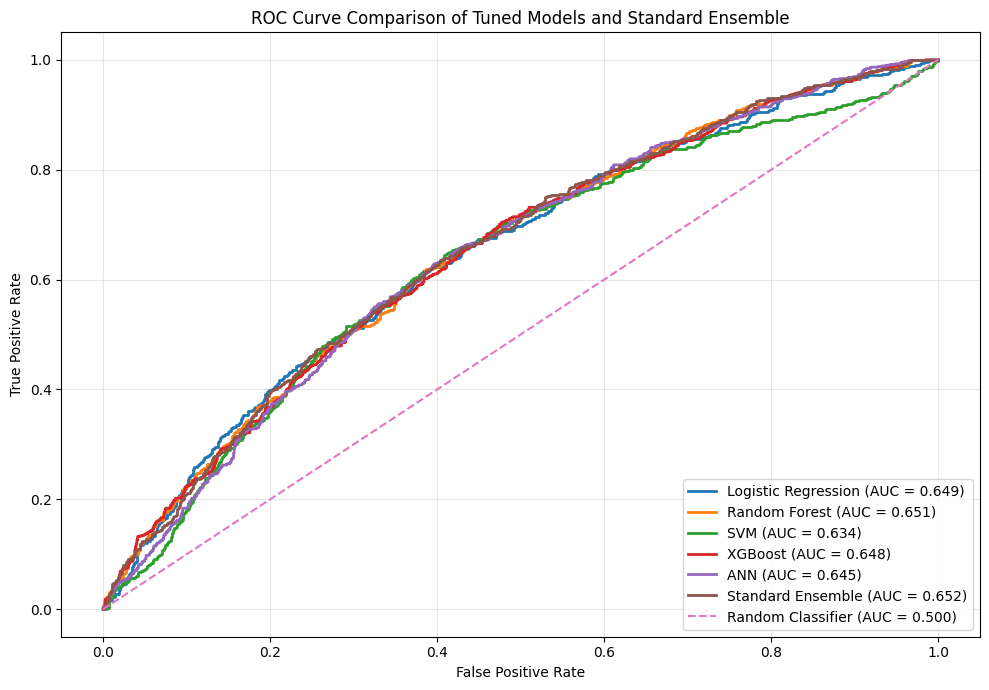

In [ ]:
# ==========================================
# ROC CURVE - TUNED MODELS + ENSEMBLE
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------
# 1. Get test scores
# ------------------------------------------------

# Logistic Regression
lr_score = lr_tuned.predict_proba(
    X_test_final
)[:, 1]

# Random Forest
rf_score = rf_tuned.predict_proba(
    X_test_final
)[:, 1]

# SVM
svm_score = svm_tuned.decision_function(
    X_test_final
)

# Normalize SVM score
svm_score_normalized = (
    svm_score - svm_score.min()
) / (
    svm_score.max() - svm_score.min()
)

# XGBoost
xgb_score = xgb_tuned.predict_proba(
    X_test_final
)[:, 1]

# ANN
ann_score = ann_tuned.predict(
    X_test_final,
    verbose=0
).ravel()


# ------------------------------------------------
# 2. Standard Ensemble Score
# ------------------------------------------------

ensemble_score = (
    svm_score_normalized +
    rf_score +
    xgb_score
) / 3


# ------------------------------------------------
# 3. Store all model scores
# ------------------------------------------------

model_scores = {
    "Logistic Regression": lr_score,
    "Random Forest": rf_score,
    "SVM": svm_score,
    "XGBoost": xgb_score,
    "ANN": ann_score,
    "Standard Ensemble": ensemble_score
}


# ------------------------------------------------
# 4. Plot ROC Curves
# ------------------------------------------------

plt.figure(figsize=(10, 7))

for model_name, score in model_scores.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        score
    )

    auc = roc_auc_score(
        y_test,
        score
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc:.3f})"
    )


# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)


# ------------------------------------------------
# 5. Formatting
# ------------------------------------------------

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison of Tuned Models and Standard Ensemble"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

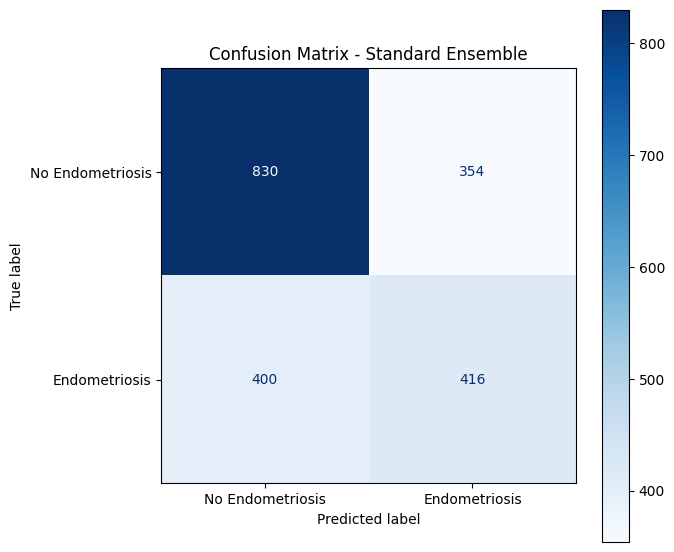

In [ ]:
# ==========================================
# CONFUSION MATRIX - STANDARD ENSEMBLE
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred_ensemble
)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Endometriosis", "Endometriosis"]
)

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

ax.set_title(
    "Confusion Matrix - Standard Ensemble"
)

plt.tight_layout()
plt.show()

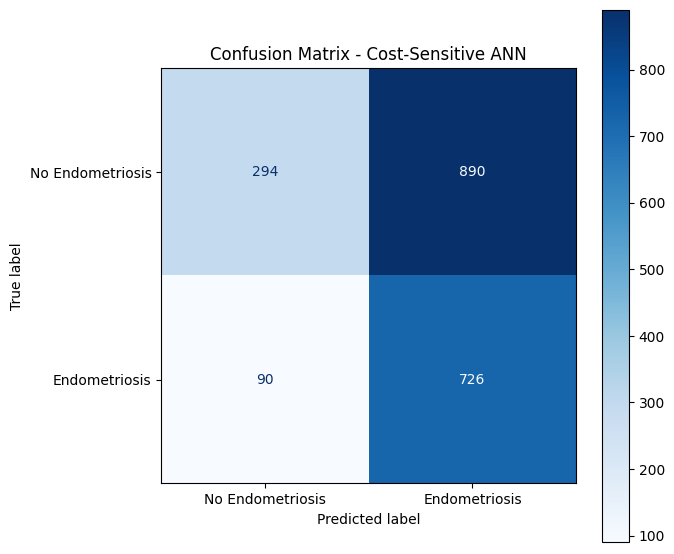

In [ ]:
# ==========================================
# CONFUSION MATRIX - COST-SENSITIVE ANN
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_cs_ann = confusion_matrix(
    y_test,
    y_test_pred_ann_cost
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cs_ann,
    display_labels=[
        "No Endometriosis",
        "Endometriosis"
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

ax.set_title(
    "Confusion Matrix - Cost-Sensitive ANN"
)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# FINAL RESULTS COMPARISON TABLE
# ==========================================

import pandas as pd

final_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "XGBoost",
        "ANN",
        "Standard Ensemble",
        "CS-Logistic Regression",
        "CS-Random Forest",
        "CS-SVM",
        "CS-XGBoost",
        "CS-ANN"
    ],

    "Accuracy": [
        0.5925,
        0.6150,
        0.6210,
        0.6175,
        0.6115,
        0.6230,
        0.5575,
        0.5610,
        0.5740,
        0.5520,
        0.5100
    ],

    "Precision": [
        0.5000,
        0.5259,
        0.5347,
        0.5306,
        0.5208,
        0.5403,
        0.4750,
        0.4768,
        0.4854,
        0.4707,
        0.4493
    ],

    "Recall": [
        0.4853,
        0.5723,
        0.5478,
        0.5417,
        0.5993,
        0.5098,
        0.8027,
        0.7794,
        0.7316,
        0.7880,
        0.8897
    ],

    "Specificity": [
        0.6655,
        0.6444,
        0.6715,
        0.6698,
        0.6199,
        0.7010,
        0.3885,
        0.4105,
        0.4654,
        0.3894,
        0.2483
    ],

    "F1-Score": [
        0.4925,
        0.5481,
        0.5412,
        0.5361,
        0.5573,
        0.5246,
        0.5968,
        0.5916,
        0.5836,
        0.5894,
        0.5970
    ],

    "ROC-AUC": [
        0.6030,
        0.6510,
        0.6339,
        0.6481,
        0.6445,
        0.6520,
        0.6561,
        0.6498,
        0.6387,
        0.6430,
        0.6516
    ]
})

# Convert to percentage
percentage_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-Score",
    "ROC-AUC"
]

final_results_display = final_results.copy()

for col in percentage_columns:
    final_results_display[col] = (
        final_results_display[col] * 100
    ).round(2).astype(str) + "%"

print("=" * 100)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 100)

display(final_results_display)

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC
0,Logistic Regression,59.25%,50.0%,48.53%,66.55%,49.25%,60.3%
1,Random Forest,61.5%,52.59%,57.23%,64.44%,54.81%,65.1%
2,SVM,62.1%,53.47%,54.78%,67.15%,54.12%,63.39%
3,XGBoost,61.75%,53.06%,54.17%,66.98%,53.61%,64.81%
4,ANN,61.15%,52.08%,59.93%,61.99%,55.73%,64.45%
5,Standard Ensemble,62.3%,54.03%,50.98%,70.1%,52.46%,65.2%
6,CS-Logistic Regression,55.75%,47.5%,80.27%,38.85%,59.68%,65.61%
7,CS-Random Forest,56.1%,47.68%,77.94%,41.05%,59.16%,64.98%
8,CS-SVM,57.4%,48.54%,73.16%,46.54%,58.36%,63.87%
9,CS-XGBoost,55.2%,47.07%,78.8%,38.94%,58.94%,64.3%


#SHAP

In [ ]:
# ==========================================
# SHAP VALUE SHAPE CHECK
# ==========================================

print("X_shap shape:", X_shap.shape)
print("SHAP values type:", type(shap_values))

if isinstance(shap_values, list):
    print("SHAP values length:", len(shap_values))
    for i, sv in enumerate(shap_values):
        print(f"Class {i} shape:", sv.shape)
else:
    print("SHAP values shape:", shap_values.shape)

X_shap shape: (500, 20)
SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (500, 20, 2)


Class 1 SHAP shape: (500, 20)


/tmp/ipykernel_53599/3843134408.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


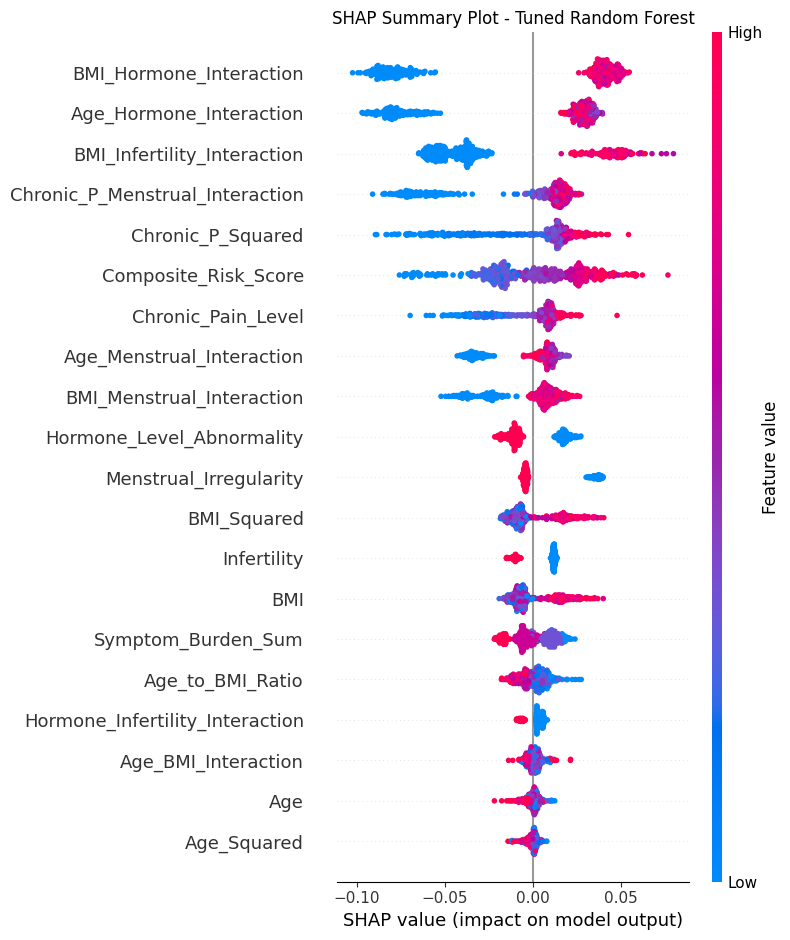

In [ ]:
# ==========================================
# SHAP SUMMARY PLOT - CLASS 1
# ENDOMETRIOSIS PREDICTION
# ==========================================

import matplotlib.pyplot as plt
import shap

# Select SHAP values for Class 1
shap_values_class1 = shap_values[:, :, 1]

print("Class 1 SHAP shape:", shap_values_class1.shape)

# SHAP Summary / Beeswarm Plot
shap.summary_plot(
    shap_values_class1,
    X_shap,
    show=False
)

plt.title(
    "SHAP Summary Plot - Tuned Random Forest"
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_53599/1175264468.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


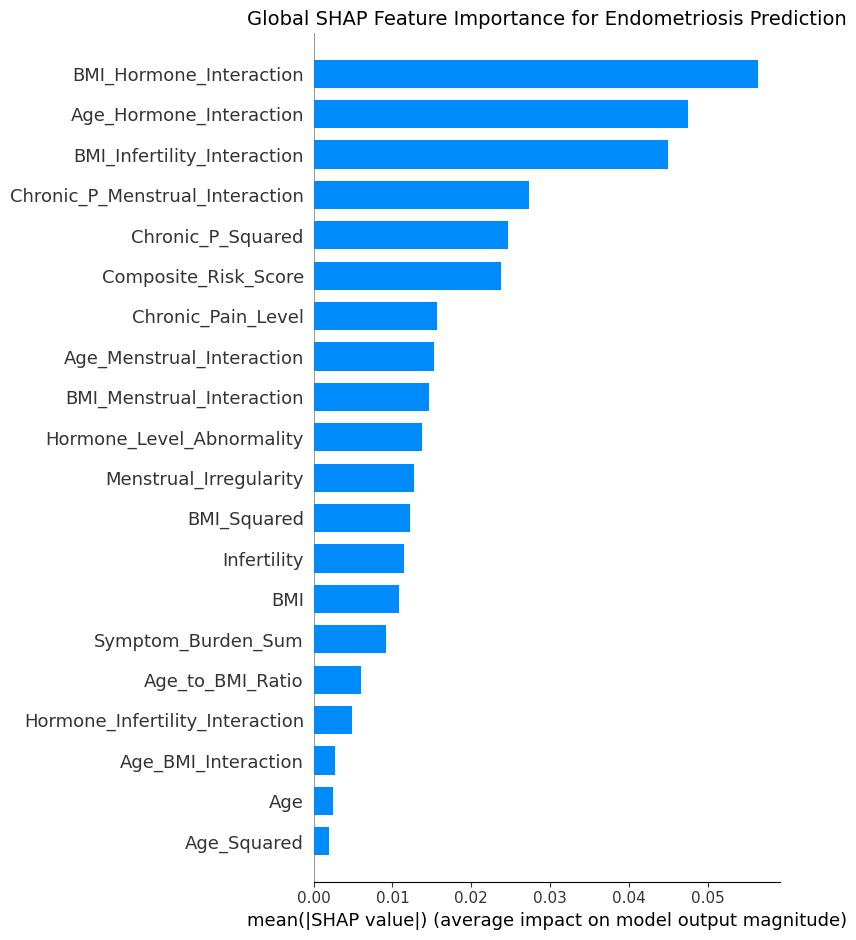

In [ ]:
# ==========================================
# SHAP GLOBAL FEATURE IMPORTANCE - BAR PLOT
# ==========================================

import shap
import matplotlib.pyplot as plt

# Class 1 = Endometriosis
shap_values_class1 = shap_values[:, :, 1]

# Global feature importance
shap.summary_plot(
    shap_values_class1,
    X_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance for Endometriosis Prediction",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# SHAP FEATURE IMPORTANCE RANKING
# ==========================================

import numpy as np
import pandas as pd

# Mean absolute SHAP value
mean_abs_shap = np.abs(
    shap_values_class1
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean |SHAP|": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by="Mean |SHAP|",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("SHAP FEATURE IMPORTANCE RANKING")
print("=" * 60)

display(shap_importance)

SHAP FEATURE IMPORTANCE RANKING


,Feature,Mean |SHAP|
0,BMI_Hormone_Interaction,0.056335
1,Age_Hormone_Interaction,0.047503
2,BMI_Infertility_Interaction,0.044925
3,Chronic_P_Menstrual_Interaction,0.027280
4,Chronic_P_Squared,0.024708
5,Composite_Risk_Score,0.023815
6,Chronic_Pain_Level,0.015635
7,Age_Menstrual_Interaction,0.015207
8,BMI_Menstrual_Interaction,0.014685
9,Hormone_Level_Abnormality,0.013773


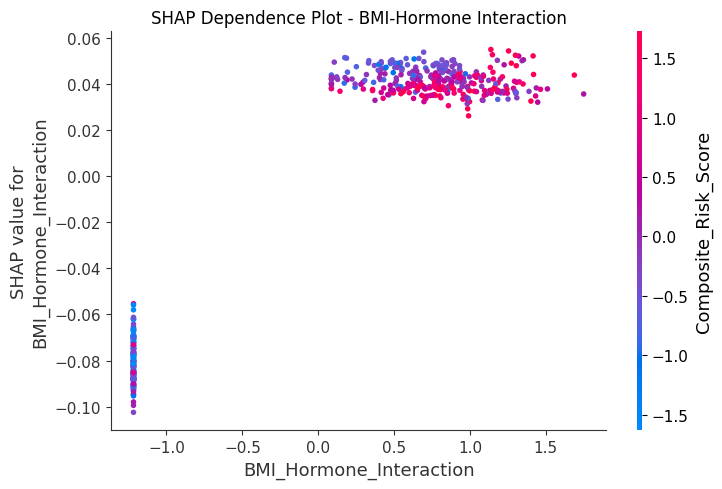

In [ ]:
# ==========================================
# SHAP DEPENDENCE PLOT - TOP FEATURE
# ==========================================

import shap
import matplotlib.pyplot as plt

shap.dependence_plot(
    "BMI_Hormone_Interaction",
    shap_values_class1,
    X_shap,
    show=False
)

plt.title(
    "SHAP Dependence Plot - BMI-Hormone Interaction"
)

plt.tight_layout()
plt.show()